<a href="https://colab.research.google.com/github/oumaymazerrik/Arabic-Sarcasm-Detection/blob/main/TP2_Arabic_Sarcasm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **1 Chargement du dataset ArSarcasm-v2**



---




In [3]:
import torch
import pandas as pd
import sklearn

print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch : 2.11.0+cpu
GPU disponible : False
GPU : CPU


In [4]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"

df = pd.read_csv(BASE + "training_data.csv")
test = pd.read_csv(BASE + "testing_data.csv")

print("Train :", df.shape)
print("Test :", test.shape)

df.head()

Train : (12548, 4)
Test : (3000, 4)


,tweet,sarcasm,sentiment,dialect
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...",False,NEU,msa
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...",False,NEU,msa
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,True,NEG,msa
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...",True,NEG,gulf
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...",False,NEU,msa


## **2-EDA**

1-Dimensions et structure du dataset

In [3]:
print("Dimensions :", df.shape)

print("\nColonnes :", df.columns.tolist())

print("\nTypes des variables :")
df.dtypes

Dimensions : (12548, 4)

Colonnes : ['tweet', 'sarcasm', 'sentiment', 'dialect']

Types des variables :


,0
tweet,object
sarcasm,bool
sentiment,object
dialect,object


2-valeurs manquantes et doublons

In [4]:
# Valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# Doublons
print("\nLignes dupliquées :", df.duplicated().sum())
print("Tweets dupliqués :", df.duplicated(subset=["tweet"]).sum())

Valeurs manquantes :
tweet        0
sarcasm      0
sentiment    0
dialect      0
dtype: int64

Lignes dupliquées : 16
Tweets dupliqués : 61


3-Distribution des labels (Sarcastique / Non sarcastique)

sarcasm
False    10380
True      2168
Name: count, dtype: int64

Pourcentages :
sarcasm
False    82.722346
True     17.277654
Name: proportion, dtype: float64


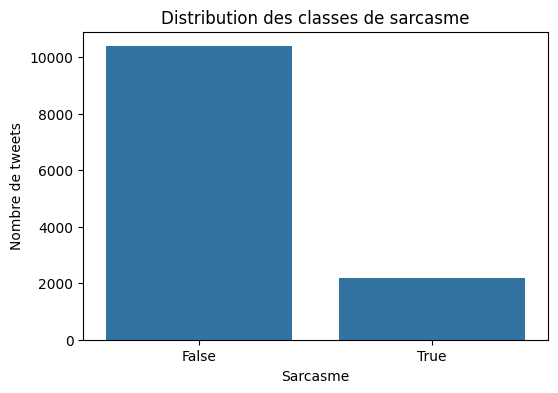

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution des classes
print(df["sarcasm"].value_counts())
print("\nPourcentages :")
print(df["sarcasm"].value_counts(normalize=True) * 100)

# Visualisation
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sarcasm")

plt.title("Distribution des classes de sarcasme")
plt.xlabel("Sarcasme")
plt.ylabel("Nombre de tweets")
plt.show()

4-Longueur des textes

In [6]:
df["nb_caracteres"] = df["tweet"].fillna("").str.len()
df["nb_mots"] = df["tweet"].fillna("").str.split().str.len()

df[["tweet", "nb_caracteres", "nb_mots"]].head()

,tweet,nb_caracteres,nb_mots
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...",133,18
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...",51,7
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,119,16
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...",134,20
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...",111,19


In [7]:
df[["nb_caracteres", "nb_mots"]].describe()

,nb_caracteres,nb_mots
count,12548.000000,12548.000000
mean,102.904048,15.043354
std,38.164885,6.770960
min,4.000000,1.000000
25%,78.000000,10.000000
50%,108.000000,15.000000
75%,133.000000,20.000000
max,303.000000,61.000000


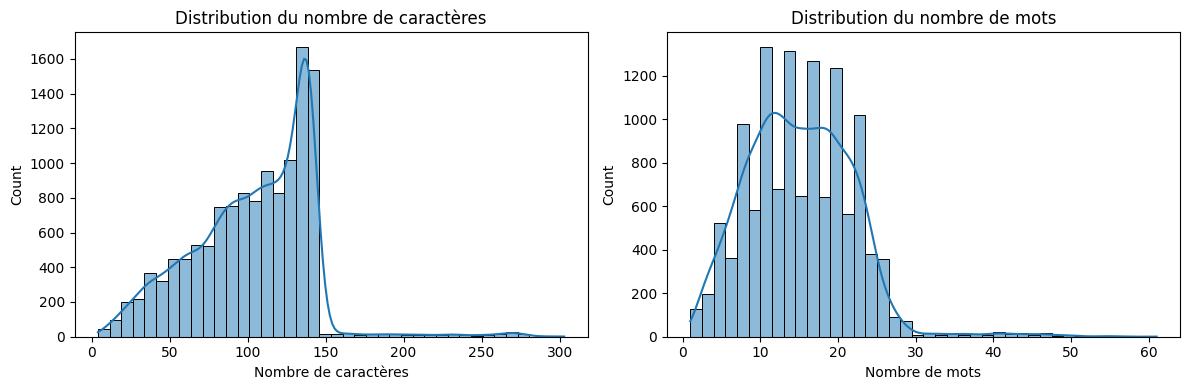

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution des caractères
sns.histplot(df["nb_caracteres"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution du nombre de caractères")
axes[0].set_xlabel("Nombre de caractères")

# Distribution des mots
sns.histplot(df["nb_mots"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribution du nombre de mots")
axes[1].set_xlabel("Nombre de mots")

plt.tight_layout()
plt.show()

5-Mots les plus fréquents

In [9]:
from collections import Counter
import matplotlib.pyplot as plt

# Regrouper tous les tweets
texte = " ".join(df["tweet"].fillna("").astype(str))

# Séparer les mots
mots = texte.split()

# Compter les occurrences
frequences = Counter(mots)

# Afficher les 20 mots les plus fréquents
top20 = frequences.most_common(20)

display(pd.DataFrame(top20, columns=["Mot", "Fréquence"]))

,Mot,Fréquence
0,في,3740
1,من,3242
2,على,1895
3,و,1685
4,"""RT",1287
5,عن,802
6,ما,745
7,مع,728
8,لا,717
9,الله,651


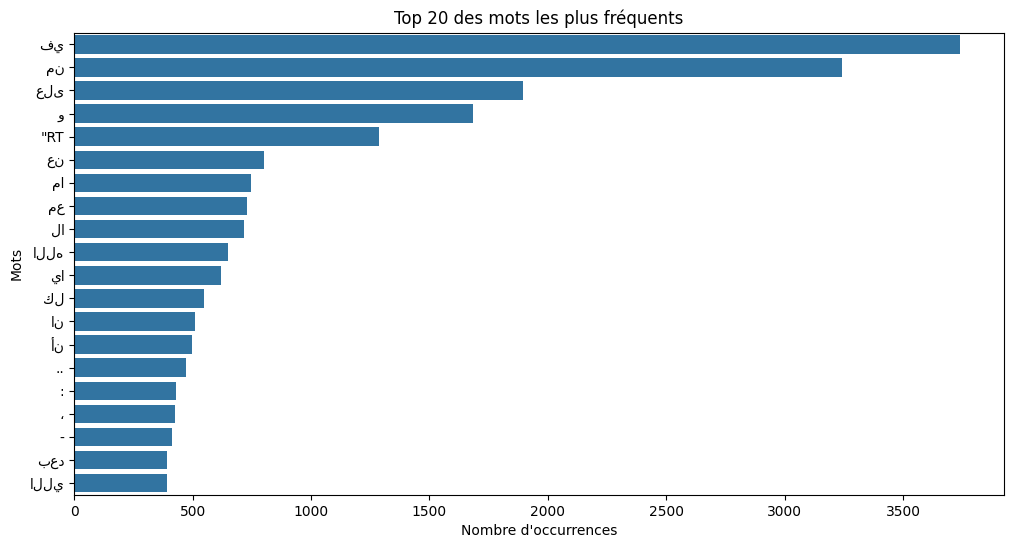

In [10]:
mots_top = [mot for mot, count in top20]
counts = [count for mot, count in top20]

plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=mots_top)

plt.title("Top 20 des mots les plus fréquents")
plt.xlabel("Nombre d'occurrences")
plt.ylabel("Mots")
plt.show()

6-Visualisation des mots par classe

In [11]:
from collections import Counter

# Tweets sarcastiques
tweets_sarc = df[df["sarcasm"] == True]["tweet"].fillna("")
mots_sarc = Counter(" ".join(tweets_sarc).split())

# Tweets non sarcastiques
tweets_non_sarc = df[df["sarcasm"] == False]["tweet"].fillna("")
mots_non_sarc = Counter(" ".join(tweets_non_sarc).split())

top_sarc = pd.DataFrame(mots_sarc.most_common(20),
                        columns=["Mot", "Fréquence"])

top_non_sarc = pd.DataFrame(mots_non_sarc.most_common(20),
                            columns=["Mot", "Fréquence"])

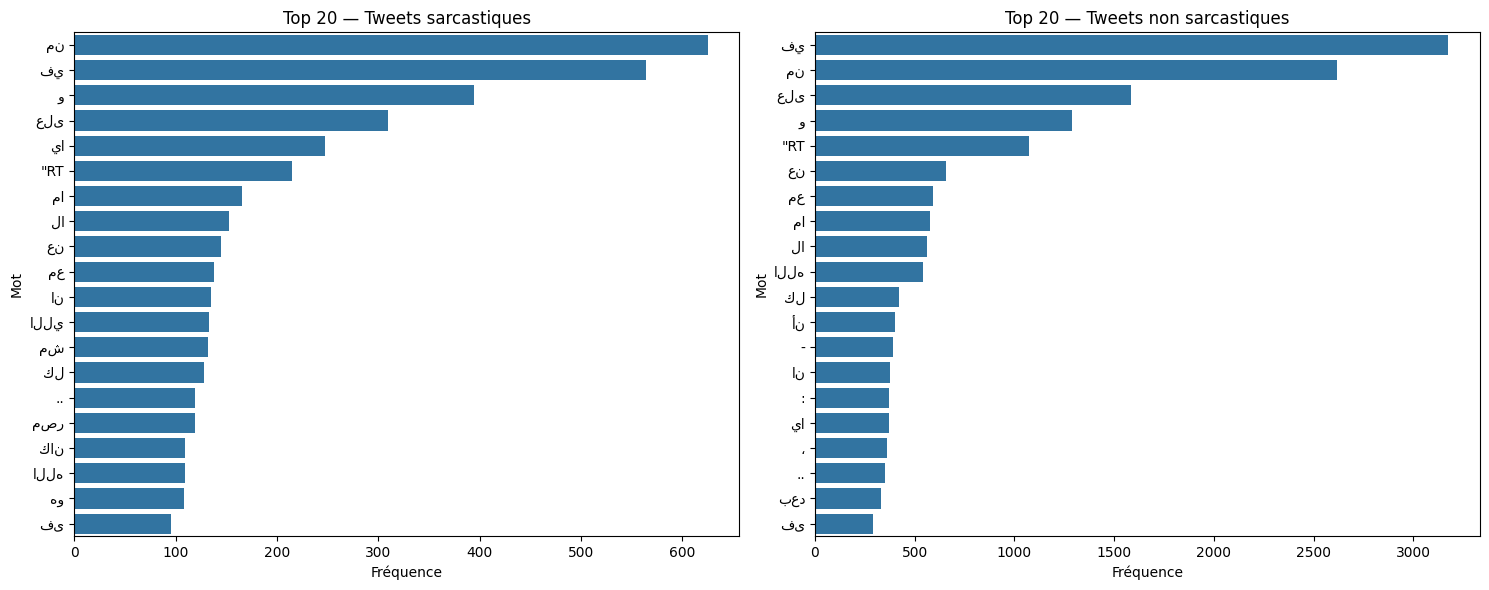

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(data=top_sarc, x="Fréquence", y="Mot", ax=axes[0])
axes[0].set_title("Top 20 — Tweets sarcastiques")

sns.barplot(data=top_non_sarc, x="Fréquence", y="Mot", ax=axes[1])
axes[1].set_title("Top 20 — Tweets non sarcastiques")

plt.tight_layout()
plt.show()

7-Analyse des emojis, hashtags, mentions et URLs

In [14]:
!pip install emoji --quiet

import re
import emoji

df["has_url"] = df["tweet"].str.contains(r"http\S+|www\.\S+", na=False)
df["has_mention"] = df["tweet"].str.contains(r"@\w+", na=False)
df["has_hashtag"] = df["tweet"].str.contains(r"#\w+", na=False)
df["has_emoji"] = df["tweet"].fillna("").apply(
    lambda x: bool(emoji.emoji_list(x))
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 17.1 MB/s eta 0:00:00


has_url        4831
has_mention    2939
has_hashtag    5944
has_emoji      1528
dtype: int64


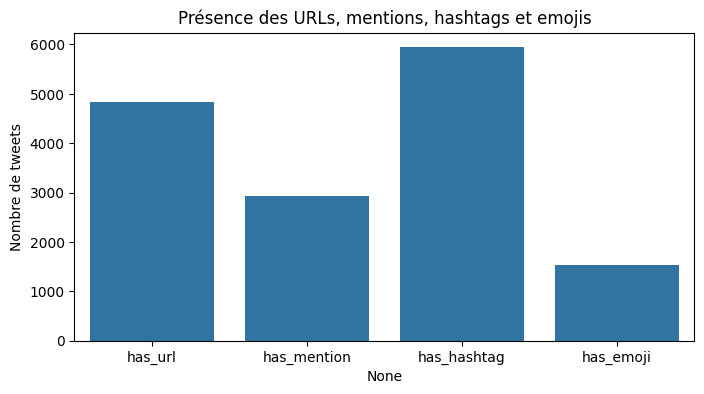

In [16]:
colonnes = ["has_url", "has_mention", "has_hashtag", "has_emoji"]

frequences = df[colonnes].sum()
print(frequences)

plt.figure(figsize=(8, 4))
sns.barplot(x=frequences.index, y=frequences.values)
plt.title("Présence des URLs, mentions, hashtags et emojis")
plt.ylabel("Nombre de tweets")
plt.show()

In [17]:
for col in colonnes:
    print(f"\n{col}")
    print(df.groupby(col)["sarcasm"].mean() * 100)


has_url
has_url
False    23.817546
True      6.830884
Name: sarcasm, dtype: float64

has_mention
has_mention
False    17.358726
True     17.012589
Name: sarcasm, dtype: float64

has_hashtag
has_hashtag
False    19.518474
True     14.788022
Name: sarcasm, dtype: float64

has_emoji
has_emoji
False    17.350272
True     16.753927
Name: sarcasm, dtype: float64


# 3-Étapes du prétraitement — Détection du sarcasme

1-Sauvegarde du texte original

In [21]:
# Sauvegarder le texte original
df["text_original"] = df["tweet"].copy()
test["text_original"] = test["tweet"].copy()

# Vérification
df[["tweet", "text_original"]].head()

,tweet,text_original
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...","""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر..."
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...","""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb..."
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...","""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf..."
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...","""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل..."


2-URL Replacement

In [22]:
import re

def replace_urls(text):
    return re.sub(r'https?://\S+|www\.\S+', 'URL', str(text))

df["text_clean"] = df["text_original"].apply(replace_urls)
test["text_clean"] = test["text_original"].apply(replace_urls)

In [23]:
df[df["text_original"].str.contains(
    r'https?://|www\.', na=False
)][["text_original", "text_clean"]].head(5)

,text_original,text_clean
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...","""مع فيدرر يا آجا والكبار 😍 URL"
5,"""طبيب #المقاصة: إصابة #أحمد_الشيخ بسيطة تحتاج ...","""طبيب #المقاصة: إصابة #أحمد_الشيخ بسيطة تحتاج ..."
8,"""Retweeted هاشتاق العرب (@TheArabHash):#فيديو ...","""Retweeted هاشتاق العرب (@TheArabHash):#فيديو ..."
9,▪️محافظ العاصمة تفقد سير العملية الانتخابية في...,▪️محافظ العاصمة تفقد سير العملية الانتخابية في...
10,"""الاتجاه: أوباما يصل الى إسرائيل للمشاركة بدفن...","""الاتجاه: أوباما يصل الى إسرائيل للمشاركة بدفن..."


3-Mention Replacement

In [24]:
def replace_mentions(text):
    return re.sub(r'@\w+', 'USER', text)

df["text_clean"] = df["text_clean"].apply(replace_mentions)
test["text_clean"] = test["text_clean"].apply(replace_mentions)

In [25]:
df[df["text_original"].str.contains(
    r'@\w+', na=False
)][["text_original", "text_clean"]].head(5)

,text_original,text_clean
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...","""USER USER USER USER USER USER USER مساكين من ..."
8,"""Retweeted هاشتاق العرب (@TheArabHash):#فيديو ...","""Retweeted هاشتاق العرب (USER):#فيديو | أهالي ..."
11,"""@Eyaaaad والله ما عليش مايمدي ايفون سبع يا حب...","""USER والله ما عليش مايمدي ايفون سبع يا حبيبي"""
14,"""@kdriyadh @nevermind330 وقت الشدة في ظنتي الج...","""USER USER وقت الشدة في ظنتي الجيش المصري حيوق..."
26,"""@WAZJ81 @a4EaA6ogaKArvKT @hjab2030 @a_1k2 الع...","""USER USER USER USER العصابة الوهابية تحارب جب..."


4-RT Removal

In [26]:
def remove_rt(text):
    return re.sub(r'\bRT\b\s*', '', text)

df["text_clean"] = df["text_clean"].apply(remove_rt)
test["text_clean"] = test["text_clean"].apply(remove_rt)

In [27]:
df[df["text_original"].str.contains(
    r'\bRT\b', na=False
)][["text_original", "text_clean"]].head(5)

,text_original,text_clean
29,"""RT @AAN_KSA1: ⁧#الارهاب_صناعه_امريكيه_لاسعودي...","""USER: ⁧#الارهاب_صناعه_امريكيه_لاسعوديه⁩ ⁧#قان..."
42,"""RT @Alkhedheiri: اللهم كما نصرت عبدك موسى في ...","""USER: اللهم كما نصرت عبدك موسى في مثل هذا الي..."
63,"""RT @algepally: شاهد: كيف كشفت روسيا إطلاق صوا...","""USER: شاهد: كيف كشفت روسيا إطلاق صواريخ باليس..."
79,"""RT @W00LF101: اللهم أنتقم منالَّذِينَ طَغَوْا...","""USER: اللهم أنتقم منالَّذِينَ طَغَوْا فِي الْ..."
85,"""RT @KaramAlhafidh: #هيج_و اصير وزيرة الصحة إل...","""USER: #هيج_و اصير وزيرة الصحة إلا اشنق عديلة ..."


5-Whitespace Cleaning

In [28]:
def clean_whitespace(text):
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["text_clean"] = df["text_clean"].apply(clean_whitespace)
test["text_clean"] = test["text_clean"].apply(clean_whitespace)

In [29]:
print(clean_whitespace("هذا    خبر \n رائع   😂"))

هذا خبر رائع 😂


6-Arabic Normalization

In [30]:
def normalize_arabic(text):
    text = re.sub(r'[أإآ]', 'ا', text)
    text = re.sub(r'ى', 'ي', text)
    return text

df["text_clean"] = df["text_clean"].apply(normalize_arabic)
test["text_clean"] = test["text_clean"].apply(normalize_arabic)

In [31]:
print(normalize_arabic("أحمد إلى المدرسة"))

احمد الي المدرسة


7-Diacritics Removal (التشكيل)

In [32]:
def remove_diacritics(text):
    return re.sub(r'[\u064B-\u0652]', '', text)

df["text_clean"] = df["text_clean"].apply(remove_diacritics)
test["text_clean"] = test["text_clean"].apply(remove_diacritics)

In [33]:
print(remove_diacritics("هٰذَا كَلَامٌ جَمِيلٌ 😂"))

هٰذا كلام جميل 😂


8-Tatweel Removal (ـ)

In [34]:
def remove_tatweel(text):
    return text.replace("ـ", "")

df["text_clean"] = df["text_clean"].apply(remove_tatweel)
test["text_clean"] = test["text_clean"].apply(remove_tatweel)

In [35]:
print(remove_tatweel("مــــرحــــبا 😂"))

مرحبا 😂


9-Sarcasm Preservation

In [36]:
import re

def sarcasm_features(text):
    return {
        "emoji": bool(emoji.emoji_list(text)),
        "hashtag": bool(re.search(r'#\w+', text)),
        "rire": bool(re.search(r'ه{3,}', text)),
        "ponctuation": bool(re.search(r'[!?؟]{2,}', text)),
        "allongement": bool(re.search(r'(.)\1{2,}', text))
    }

exemple = "يا سلام جمييييل 😂😂 #مضحك ههههه !!!"

print(sarcasm_features(exemple))

{'emoji': True, 'hashtag': True, 'rire': True, 'ponctuation': True, 'allongement': True}


10-Cleaning Validation

In [37]:
comparaison = df[["text_original", "text_clean"]].copy()

# Tweets modifiés par le nettoyage
modifies = comparaison[
    comparaison["text_original"] != comparaison["text_clean"]
]

display(modifies.head(15))

,text_original,text_clean
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...","""د. #محمود_العلايلي:اري ان الفريق #احمد_شفيق ر..."
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...","""مع فيدرر يا اجا والكبار 😍 URL"
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,“الداعون لمبدا الاختلاط بين الجنسين؛ كالداعين ...
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...","""USER USER USER USER USER USER USER مساكين من ..."
5,"""طبيب #المقاصة: إصابة #أحمد_الشيخ بسيطة تحتاج ...","""طبيب #المقاصة: اصابة #احمد_الشيخ بسيطة تحتاج ..."
6,مرسي : مش هنام اكتر من اربع ساعات في اليوم.......,مرسي : مش هنام اكتر من اربع ساعات في اليوم.......
8,"""Retweeted هاشتاق العرب (@TheArabHash):#فيديو ...","""Retweeted هاشتاق العرب (USER):#فيديو | اهالي ..."
9,▪️محافظ العاصمة تفقد سير العملية الانتخابية في...,▪️محافظ العاصمة تفقد سير العملية الانتخابية في...
10,"""الاتجاه: أوباما يصل الى إسرائيل للمشاركة بدفن...","""الاتجاه: اوباما يصل الي اسرائيل للمشاركة بدفن..."
11,"""@Eyaaaad والله ما عليش مايمدي ايفون سبع يا حب...","""USER والله ما عليش مايمدي ايفون سبع يا حبيبي"""


In [38]:
nb_modifies = len(modifies)
total = len(df)

print("Tweets modifiés :", nb_modifies)
print("Pourcentage :", round(nb_modifies / total * 100, 2), "%")

Tweets modifiés : 11145
Pourcentage : 88.82 %


Data Splitting

In [50]:
from sklearn.model_selection import train_test_split

# Ajouter un identifiant unique
df["id"] = range(len(df))
test["id"] = range(len(test))

# Stratified Split
train, val = train_test_split(
    df,
    test_size=0.10,
    random_state=42,
    stratify=df["sarcasm"]
)

print("Train :", train.shape)
print("Validation :", val.shape)
print("Test officiel :", test.shape)


Train : (11293, 13)
Validation : (1255, 13)
Test officiel : (3000, 7)


Tokenization & Encoding

In [41]:
!pip -q install transformers

In [42]:
from transformers import AutoTokenizer

model_name = "aubmindlab/bert-base-arabertv02-twitter"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Exemple de tokenisation
texte = train["text_clean"].iloc[0]

tokens = tokenizer.tokenize(texte)
ids = tokenizer.convert_tokens_to_ids(tokens)

print("Texte :", texte)
print("Tokens :", tokens)
print("IDs :", ids)

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Texte : "#لافروف: #موسكو تامل باجراء حوار بناء بشان الازمة في #سورية خلال لقائي مع وزيري خارجية #ايران و #تركيا غدا URL
Tokens : ['"', '#', 'لافروف', ':', '#', 'موسكو', 'تام', '##ل', 'باجراء', 'حوار', 'بناء', 'بشان', 'الازمة', 'في', '#', 'سورية', 'خلال', 'لقا', '##ئي', 'مع', 'وزيري', 'خارجية', '#', 'ايران', 'و', '#', 'تركيا', 'غدا', 'U', '##R', '##L']
IDs : [9, 10, 14115, 31, 10, 5338, 11153, 182, 26360, 4059, 1745, 28915, 7190, 305, 10, 3389, 492, 49407, 1464, 354, 30292, 5382, 10, 4064, 139, 10, 2726, 3214, 58, 255, 246]


Padding & Truncation

In [43]:
MAX_LEN = 128

def encode_texts(data):
    return tokenizer(
        data["text_clean"].fillna("").tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

train_enc = encode_texts(train)
val_enc = encode_texts(val)

# Test officiel : uniquement préparé
test_enc = encode_texts(test)

In [44]:
print("Train :", train_enc["input_ids"].shape)
print("Validation :", val_enc["input_ids"].shape)
print("Test :", test_enc["input_ids"].shape)

print("\nInput IDs :", train_enc["input_ids"][0][:15])
print("Attention Mask :", train_enc["attention_mask"][0][:15])

Train : torch.Size([11293, 128])
Validation : torch.Size([1255, 128])
Test : torch.Size([3000, 128])

Input IDs : tensor([    2,     9,    10, 14115,    31,    10,  5338, 11153,   182, 26360,
         4059,  1745, 28915,  7190,   305])
Attention Mask : tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


### **Class Imbalance Handling**

Class Weighting — Pondération

In [45]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = train["sarcasm"].astype(int)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

print("Poids des classes :", class_weights)

Poids des classes : [0.60442089 2.89415684]


Random Oversampling — Ré-échantillonnage

In [46]:
!pip -q install imbalanced-learn

In [47]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_resampled, y_resampled = ros.fit_resample(
    train[["text_clean"]],
    y_train
)

print("Avant :")
print(y_train.value_counts())

print("\nAprès Oversampling :")
print(y_resampled.value_counts())

Avant :
sarcasm
0    9342
1    1951
Name: count, dtype: int64

Après Oversampling :
sarcasm
0    9342
1    9342
Name: count, dtype: int64


Threshold Tuning — Optimisation du seuil

In [48]:
from sklearn.metrics import f1_score

def optimize_threshold(y_true, y_prob):
    thresholds = np.arange(0.1, 0.91, 0.01)

    scores = [
        f1_score(y_true, (y_prob >= t).astype(int))
        for t in thresholds
    ]

    best_index = np.argmax(scores)

    return thresholds[best_index], scores[best_index]

# **Partie A — Baseline : TF-IDF + Machine Learning**

Multinomial Naive Bayes



Logistic Regression



Linear SVM

#  Étape 1 : TF-IDF Vectorization

In [52]:
# Textes
X_train_text = train["text_clean"].fillna("")
X_val_text = val["text_clean"].fillna("")

# Labels
y_train = train["sarcasm"].astype(int)
y_val = val["sarcasm"].astype(int)

In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# TF-IDF sur les mots
tfidf_word = TfidfVectorizer(ngram_range=(1, 2))

# TF-IDF sur les caractères
tfidf_char = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5)
)

# Train
X_train_word = tfidf_word.fit_transform(X_train_text)
X_train_char = tfidf_char.fit_transform(X_train_text)

# Validation
X_val_word = tfidf_word.transform(X_val_text)
X_val_char = tfidf_char.transform(X_val_text)

# Combinaison des features
X_train = hstack([X_train_word, X_train_char]).tocsr()
X_val = hstack([X_val_word, X_val_char]).tocsr()

print("Train :", X_train.shape)
print("Validation :", X_val.shape)

Train : (11293, 620355)
Validation : (1255, 620355)


# ***Étape 2 : Model Training***


In [55]:
import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score
)
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import RandomOverSampler

# 1. Modèles
def get_model(name, weighted=False):
    if name == "Naive Bayes":
        return MultinomialNB()

    if name == "Logistic Regression":
        return LogisticRegression(
            class_weight="balanced" if weighted else None,
            max_iter=1000,
            random_state=42
        )

    if name == "Linear SVM":
        return LinearSVC(
            class_weight="balanced" if weighted else None,
            random_state=42
        )

# 2. Optimisation du seuil
def optimize_threshold(y_true, scores):
    thresholds = np.linspace(
        scores.min(), scores.max(), 201
    )

    best_threshold = thresholds[0]
    best_f1 = -1

    for threshold in thresholds:
        y_pred = (scores >= threshold).astype(int)
        score = f1_score(y_true, y_pred, zero_division=0)

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    return best_threshold

# 3. Oversampling sur Train uniquement
ros = RandomOverSampler(random_state=42)

X_over, y_over = ros.fit_resample(X_train, y_train)

print("Avant Oversampling:")
print(pd.Series(y_train).value_counts())

print("\nAprès Oversampling:")
print(pd.Series(y_over).value_counts())

# 4. Comparaison des 9 combinaisons
results = []
trained_models = {}

model_names = [
    "Naive Bayes",
    "Logistic Regression",
    "Linear SVM"
]

methods = [
    "Class Weighting",
    "Oversampling",
    "Threshold Tuning"
]

for name in model_names:
    for method in methods:

        model = get_model(
            name,
            weighted=(method == "Class Weighting")
        )

        if method == "Oversampling":
            model.fit(X_over, y_over)

        elif method == "Class Weighting" and name == "Naive Bayes":
            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )
            model.fit(X_train, y_train, sample_weight=weights)

        else:
            model.fit(X_train, y_train)

        # Scores de décision
        if name == "Naive Bayes" or name == "Logistic Regression":
            scores = model.predict_proba(X_val)[:, 1]
            threshold = 0.5
        else:
            scores = model.decision_function(X_val)
            threshold = 0.0

        # Optimiser le seuil uniquement pour cette méthode
        if method == "Threshold Tuning":
            threshold = optimize_threshold(y_val, scores)

        y_pred = (scores >= threshold).astype(int)

        results.append({
            "Model": name,
            "Method": method,
            "Precision": precision_score(y_val, y_pred, zero_division=0),
            "Recall": recall_score(y_val, y_pred, zero_division=0),
            "F1": f1_score(y_val, y_pred, zero_division=0),
            "Accuracy": accuracy_score(y_val, y_pred),
            "PR-AUC": average_precision_score(y_val, scores),
            "Threshold": threshold
        })

        trained_models[(name, method)] = (model, threshold)

# 5. Tableau comparatif
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

display(results_df.round(4))

Avant Oversampling:
sarcasm
0    9342
1    1951
Name: count, dtype: int64

Après Oversampling:
sarcasm
0    9342
1    9342
Name: count, dtype: int64


,Model,Method,Precision,Recall,F1,Accuracy,PR-AUC,Threshold
8,Linear SVM,Threshold Tuning,0.5084,0.5576,0.5319,0.8303,0.5404,-0.3515
4,Logistic Regression,Oversampling,0.5280,0.5207,0.5244,0.8367,0.5272,0.5000
5,Logistic Regression,Threshold Tuning,0.5185,0.5161,0.5173,0.8335,0.5193,0.2699
3,Logistic Regression,Class Weighting,0.4837,0.5484,0.5140,0.8207,0.5192,0.5000
0,Naive Bayes,Class Weighting,0.3506,0.8433,0.4953,0.7028,0.5282,0.5000
1,Naive Bayes,Oversampling,0.3561,0.7926,0.4914,0.7163,0.5293,0.5000
6,Linear SVM,Class Weighting,0.6058,0.3825,0.4689,0.8502,0.5344,0.0000
7,Linear SVM,Oversampling,0.6299,0.3687,0.4651,0.8534,0.5302,0.0000
2,Naive Bayes,Threshold Tuning,0.1729,1.0000,0.2948,0.1729,0.2860,0.0000


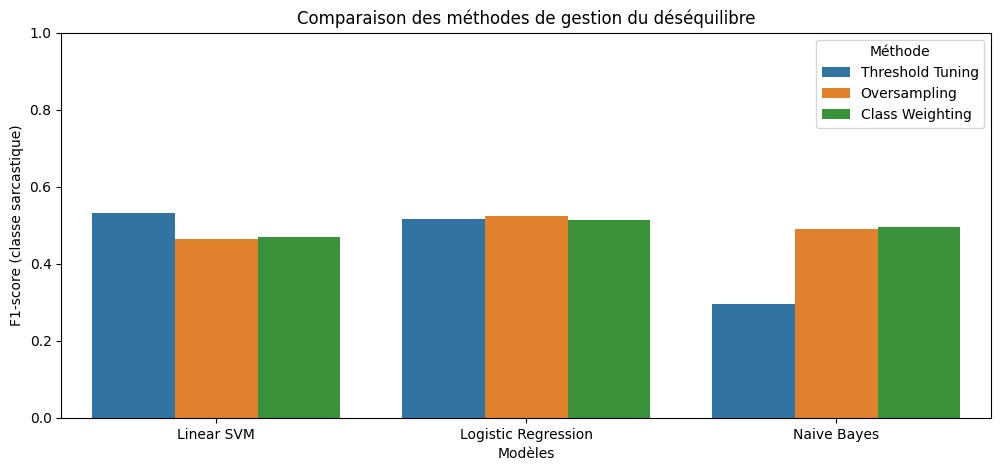

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1",
    hue="Method"
)

plt.title("Comparaison des méthodes de gestion du déséquilibre")
plt.ylabel("F1-score (classe sarcastique)")
plt.xlabel("Modèles")
plt.ylim(0, 1)
plt.legend(title="Méthode")
plt.show()

Meilleure combinaison

In [57]:
best = results_df.iloc[0]

print("Meilleur modèle :", best["Model"])
print("Meilleure méthode :", best["Method"])
print("F1-score :", round(best["F1"], 4))
print("Precision :", round(best["Precision"], 4))
print("Recall :", round(best["Recall"], 4))

Meilleur modèle : Linear SVM
Meilleure méthode : Threshold Tuning
F1-score : 0.5319
Precision : 0.5084
Recall : 0.5576


# ***Partie A — Model Evaluation & Confusion Matrix***

In [64]:
from sklearn.metrics import (
    classification_report, accuracy_score,
    average_precision_score, confusion_matrix
)

# Récupérer le meilleur modèle et son seuil
model, threshold = trained_models[("Linear SVM", "Threshold Tuning")]

# Prédictions sur Validation
scores = model.decision_function(X_val)
y_pred = (scores >= threshold).astype(int)

print("Accuracy :", round(accuracy_score(y_val, y_pred), 4))
print("PR-AUC (AP) :", round(average_precision_score(y_val, scores), 4))

print("\nClassification Report :")
print(classification_report(
    y_val, y_pred,
    target_names=["Non sarcastique", "Sarcastique"]
))

Accuracy : 0.8303
PR-AUC (AP) : 0.5404

Classification Report :
                 precision    recall  f1-score   support

Non sarcastique       0.91      0.89      0.90      1038
    Sarcastique       0.51      0.56      0.53       217

       accuracy                           0.83      1255
      macro avg       0.71      0.72      0.71      1255
   weighted avg       0.84      0.83      0.83      1255



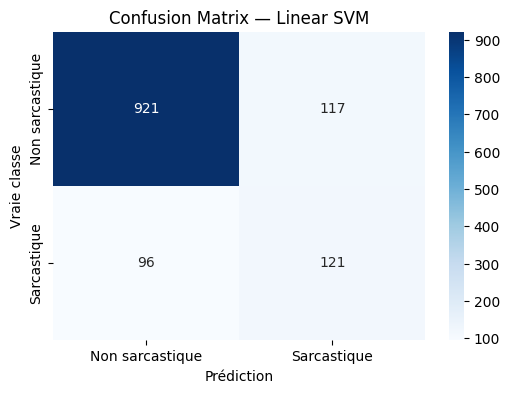

TP : 121
TN : 921
FP : 117
FN : 96


In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non sarcastique", "Sarcastique"],
    yticklabels=["Non sarcastique", "Sarcastique"]
)

plt.xlabel("Prédiction")
plt.ylabel("Vraie classe")
plt.title("Confusion Matrix — Linear SVM")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("TP :", tp)
print("TN :", tn)
print("FP :", fp)
print("FN :", fn)

# **Partie A — Stop Words Experiment**

Préparer les Stop Words arabes

In [66]:
import nltk
nltk.download("stopwords", quiet=True)

from nltk.corpus import stopwords

arabic_stopwords = set(stopwords.words("arabic"))

# Conserver les négations
negations = {
    "لا", "لم", "لن", "ليس", "ليست",
    "ما", "مش", "مو", "مش", "غير"
}

arabic_stopwords = arabic_stopwords - negations

print("Nombre de Stop Words :", len(arabic_stopwords))

Nombre de Stop Words : 694


In [67]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
from scipy.sparse import hstack
import pandas as pd

# Configuration sans stop words
def remove_stopwords(text):
    return " ".join(
        mot for mot in text.split()
        if mot not in arabic_stopwords
    )

experiments = {
    "Avec Stop Words": (
        train["text_clean"].fillna(""),
        val["text_clean"].fillna("")
    ),
    "Sans Stop Words": (
        train["text_clean"].fillna("").apply(remove_stopwords),
        val["text_clean"].fillna("").apply(remove_stopwords)
    )
}

results_stopwords = []

# Même hyperparamètre C pour les deux configurations
C_value = 1.0

for name, (train_text, val_text) in experiments.items():

    tf_word = TfidfVectorizer(ngram_range=(1, 2))
    tf_char = TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5)
    )

    X_tr = hstack([
        tf_word.fit_transform(train_text),
        tf_char.fit_transform(train_text)
    ]).tocsr()

    X_v = hstack([
        tf_word.transform(val_text),
        tf_char.transform(val_text)
    ]).tocsr()

    model = LinearSVC(C=C_value, random_state=42)
    model.fit(X_tr, y_train)

    scores = model.decision_function(X_v)
    threshold = optimize_threshold(y_val, scores)

    predictions = (scores >= threshold).astype(int)

    results_stopwords.append({
        "Configuration": name,
        "F1-score": f1_score(y_val, predictions),
        "Threshold": threshold
    })

display(pd.DataFrame(results_stopwords).round(4))

,Configuration,F1-score,Threshold
0,Avec Stop Words,0.5319,-0.3515
1,Sans Stop Words,0.5506,-0.4070


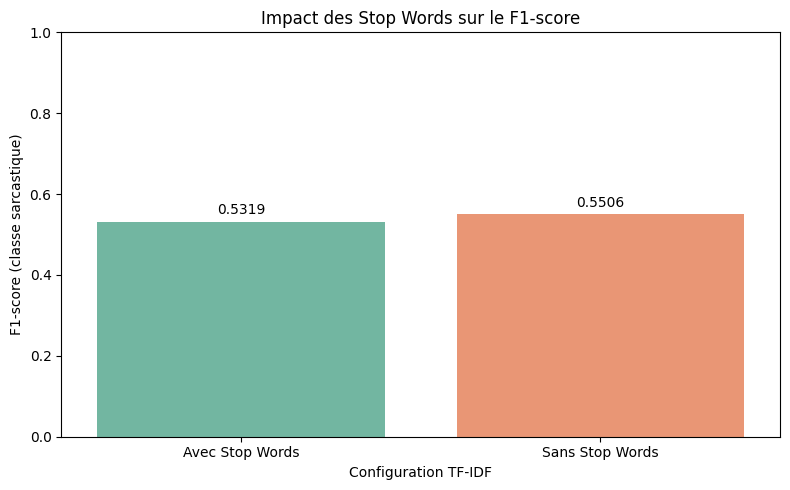

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

results_sw = pd.DataFrame(results_stopwords)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results_sw,
    x="Configuration",
    y="F1-score",
    hue="Configuration",
    palette="Set2",
    legend=False
)

# Afficher les valeurs sur les barres
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("Impact des Stop Words sur le F1-score")
plt.xlabel("Configuration TF-IDF")
plt.ylabel("F1-score (classe sarcastique)")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

On peut donc conclure que, dans notre cas, enlever les stop words a aidé le modèle à mieux détecter le sarcasme.
Ainsi, pour la suite, nous retenons la configuration sans stop words comme meilleure option pour la baseline.

On retient notre meilleure baseline :
- Modèle : Linear SVM
- Features : TF-IDF (mots + caractères)
- Prétraitement : sans Stop Words, avec conservation des négations
- Méthode : Threshold Tuning
- F1-score Validation : 0.5506
- Seuil : -0.4070

In [71]:
best_threshold = -0.4070

joblib.dump({
    "model": best_model,
    "tfidf_word": tf_word,
    "tfidf_char": tf_char,
    "threshold": best_threshold,
    "stopwords": arabic_stopwords
}, "models/baseline_svm.joblib")

print("Seuil sauvegardé :", joblib.load("models/baseline_svm.joblib")["threshold"])

Seuil sauvegardé : -0.407


In [72]:
saved = joblib.load("models/baseline_svm.joblib")

print("Modèle :", type(saved["model"]).__name__)
print("Seuil :", saved["threshold"])

Modèle : LinearSVC
Seuil : -0.407


# ***Partie B — Étape B.1 : Zero-Shot Classification (NLI)***

In [73]:
from transformers import pipeline
import torch

model_name = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"

zs = pipeline(
    "zero-shot-classification",
    model=model_name,
    device=0 if torch.cuda.is_available() else -1
)

print("Modèle chargé avec succès !")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Modèle chargé avec succès !


In [74]:
tweet = "يا سلام على الخدمة الممتازة، انتظرت 5 ساعات 😂"

result = zs(
    tweet,
    candidate_labels=["ساخرة", "جادة"],
    hypothesis_template="هذه التغريدة {}."
)

print("Labels :", result["labels"])
print("Scores :", result["scores"])

Labels : ['جادة', 'ساخرة']
Scores : [0.632729709148407, 0.36727026104927063]


Prédictions sur Validation

In [75]:
from tqdm.auto import tqdm
import numpy as np

texts = val["text_clean"].fillna("").tolist()

labels = ["ساخرة", "جادة"]
scores_sarcasm = []

for i in tqdm(range(0, len(texts), 16)):
    batch = texts[i:i+16]

    results = zs(
        batch,
        candidate_labels=labels,
        hypothesis_template="هذه التغريدة {}.",
        batch_size=16,
        truncation=True
    )

    for result in results:
        score = dict(zip(result["labels"], result["scores"]))
        scores_sarcasm.append(score["ساخرة"])

scores_sarcasm = np.array(scores_sarcasm)

print("Tweets évalués :", len(scores_sarcasm))

  0%|          | 0/79 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Tweets évalués : 1255


In [76]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score
)

y_val = val["sarcasm"].astype(int).values

y_pred_zs = (scores_sarcasm >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_val, y_pred_zs), 4))
print("Precision :", round(precision_score(y_val, y_pred_zs, zero_division=0), 4))
print("Recall :", round(recall_score(y_val, y_pred_zs, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, y_pred_zs, zero_division=0), 4))
print("PR-AUC (AP) :", round(average_precision_score(y_val, scores_sarcasm), 4))

Accuracy : 0.3012
Precision : 0.1933
Recall : 0.9585
F1-score : 0.3217
PR-AUC (AP) : 0.3459


le modèle détecte presque tous les tweets sarcastiques (Recall élevé), mais classe beaucoup de tweets non sarcastiques comme sarcastiques (Precision faible).

# ***Partie B.2 — Sentiment-Based Heuristic-CAMeLBERT***

In [80]:
from transformers import pipeline
import torch

sa = pipeline(
    "text-classification",
    model="CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment",
    device=0 if torch.cuda.is_available() else -1
)

print(sa.model.config.id2label)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

{0: 'positive', 1: 'negative', 2: 'neutral'}


In [81]:
from tqdm.auto import tqdm
import numpy as np

texts = val["text_clean"].fillna("").tolist()
sentiment_labels = []

for i in tqdm(range(0, len(texts), 16)):
    results = sa(
        texts[i:i+16],
        batch_size=16,
        truncation=True
    )

    sentiment_labels.extend([r["label"] for r in results])

# Negative = sarcastique
y_pred_sentiment = np.array([
    1 if label.lower() == "negative" else 0
    for label in sentiment_labels
])

print("Tweets évalués :", len(y_pred_sentiment))

  0%|          | 0/79 [00:00<?, ?it/s]

Tweets évalués : 1255


In [82]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

print("Accuracy :", round(accuracy_score(y_val, y_pred_sentiment), 4))
print("Precision :", round(precision_score(y_val, y_pred_sentiment), 4))
print("Recall :", round(recall_score(y_val, y_pred_sentiment), 4))
print("F1-score :", round(f1_score(y_val, y_pred_sentiment), 4))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_sentiment))

Accuracy : 0.6813
Precision : 0.3264
Recall : 0.7926
F1-score : 0.4624

Confusion Matrix :
[[683 355]
 [ 45 172]]


CAMeLBERT détecte une grande partie des tweets sarcastiques (Recall = 79,26 %), mais produit beaucoup de faux positifs. Cela confirme qu'un sentiment négatif n'implique pas nécessairement du sarcasme.

# ***Partie C — Static Embeddings + Deep Learning (BiLSTM)***

Tokenization & Vocabulary Building

Whitespace Tokenization

In [83]:
# Tokenisation en mots
train_tokens = train["text_clean"].fillna("").apply(str.split)
val_tokens = val["text_clean"].fillna("").apply(str.split)

print("Exemple :", train_tokens.iloc[0])

Exemple : ['"#لافروف:', '#موسكو', 'تامل', 'باجراء', 'حوار', 'بناء', 'بشان', 'الازمة', 'في', '#سورية', 'خلال', 'لقائي', 'مع', 'وزيري', 'خارجية', '#ايران', 'و', '#تركيا', 'غدا', 'URL']


Construction du vocabulaire :On conserve uniquement les mots présents au moins 2 fois dans Train

In [84]:
from collections import Counter

# Compter les mots
word_counts = Counter(
    word for tokens in train_tokens for word in tokens
)

# Tokens spéciaux
vocab = {"<PAD>": 0, "<UNK>": 1}

# Mots avec fréquence >= 2
for word, count in word_counts.items():
    if count >= 2:
        vocab[word] = len(vocab)

print("Taille du vocabulaire :", len(vocab))

Taille du vocabulaire : 16080


Random Embeddings

In [86]:
import torch
import torch.nn as nn

embedding_dim = 100

embedding_layer = nn.Embedding(
    num_embeddings=len(vocab),
    embedding_dim=embedding_dim,
    padding_idx=0
)

print("Taille du vocabulaire :", len(vocab))
print("Dimensions des embeddings :", embedding_layer.weight.shape)

Taille du vocabulaire : 16080
Dimensions des embeddings : torch.Size([16080, 100])


Sequence Encoding & Padding

In [88]:
import torch

MAX_LEN = 128

def prepare_sequences(data):
    sequences = []

    for text in data["text_clean"].fillna(""):
        tokens = text.split()
        ids = [vocab.get(word, vocab["<UNK>"]) for word in tokens]

        ids = ids[:MAX_LEN]
        ids += [vocab["<PAD>"]] * (MAX_LEN - len(ids))

        sequences.append(ids)

    return torch.tensor(sequences, dtype=torch.long)

X_train_seq = prepare_sequences(train)
X_val_seq = prepare_sequences(val)

print("Train :", X_train_seq.shape)
print("Validation :", X_val_seq.shape)

Train : torch.Size([11293, 128])
Validation : torch.Size([1255, 128])


Training du BiLSTM

In [92]:
import torch
import torch.nn as nn
import numpy as np
import copy

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

# ==========================================
# 1. Configuration
# ==========================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

torch.manual_seed(42)
np.random.seed(42)

# ==========================================
# 2. Préparation des données
# ==========================================

MAX_LEN = 128

def prepare_sequences(data):
    sequences = []

    for text in data["text_clean"].fillna(""):
        tokens = text.split()
        ids = [vocab.get(word, vocab["<UNK>"]) for word in tokens]
        ids = ids[:MAX_LEN]
        ids += [vocab["<PAD>"]] * (MAX_LEN - len(ids))
        sequences.append(ids)

    return torch.tensor(sequences, dtype=torch.long)

X_train_seq = prepare_sequences(train)
X_val_seq = prepare_sequences(val)

y_train = train["sarcasm"].astype(int).to_numpy()
y_val = val["sarcasm"].astype(int).to_numpy()

train_loader = DataLoader(
    TensorDataset(
        X_train_seq,
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        X_val_seq,
        torch.tensor(y_val, dtype=torch.long)
    ),
    batch_size=32
)

# ==========================================
# 3. Architecture BiLSTM
# ==========================================

class BiLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, x):
        embedded = self.embedding(x)
        output, _ = self.lstm(embedded)

        mask = (x != 0).unsqueeze(-1)
        output = output.masked_fill(~mask, -1e9)

        pooled = output.max(dim=1).values
        return self.fc(pooled)

model_bilstm = BiLSTM(len(vocab)).to(device)

# ==========================================
# 4. Loss et Optimizer
# ==========================================

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

weights = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.Adam(
    model_bilstm.parameters(),
    lr=0.001
)

# ==========================================
# 5. Training + Validation
# ==========================================

best_f1 = -1
best_state = None
patience = 3
counter = 0

for epoch in range(15):

    model_bilstm.train()
    total_loss = 0

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()

        outputs = model_bilstm(X)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Validation
    model_bilstm.eval()
    predictions = []
    true_labels = []

    with torch.no_grad():
        for X, y in val_loader:
            outputs = model_bilstm(X.to(device))
            preds = outputs.argmax(dim=1).cpu().numpy()

            predictions.extend(preds)
            true_labels.extend(y.numpy())

    f1 = f1_score(true_labels, predictions, zero_division=0)

    print(
        f"Epoch {epoch+1} | "
        f"Loss: {total_loss / len(train_loader):.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_state = copy.deepcopy(model_bilstm.state_dict())
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early Stopping")
        break

# ==========================================
# 6. Restaurer le meilleur modèle
# ==========================================

model_bilstm.load_state_dict(best_state)

print("\nMeilleur F1-score Validation :", round(best_f1, 4))

Device : cuda
Epoch 1 | Loss: 0.6196 | F1: 0.4211
Epoch 2 | Loss: 0.5016 | F1: 0.4346
Epoch 3 | Loss: 0.3445 | F1: 0.4418
Epoch 4 | Loss: 0.1915 | F1: 0.4366
Epoch 5 | Loss: 0.0980 | F1: 0.4439
Epoch 6 | Loss: 0.0542 | F1: 0.4371
Epoch 7 | Loss: 0.0342 | F1: 0.4010
Epoch 8 | Loss: 0.0288 | F1: 0.4068
Early Stopping

Meilleur F1-score Validation : 0.4439


BiLSTM + AraVec (Frozen vs Unfrozen)

In [97]:
# ======================================
# 8. Training Function
# ======================================

def train_model(frozen=True):

    torch.manual_seed(42)

    model = BiLSTMAraVec(
        embedding_matrix,
        frozen=frozen
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    best_f1 = -1
    best_state = None
    counter = 0
    patience = 3

    for epoch in range(15):

        # Training
        model.train()
        total_loss = 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            optimizer.zero_grad()

            outputs = model(X)
            loss = criterion(outputs, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Validation
        model.eval()
        predictions = []
        true_labels = []

        with torch.no_grad():
            for X, y in val_loader:
                X = X.to(device)

                outputs = model(X)
                preds = outputs.argmax(dim=1).cpu().numpy()

                predictions.extend(preds)
                true_labels.extend(y.numpy())

        f1 = f1_score(true_labels, predictions, zero_division=0)

        print(
            f"Epoch {epoch+1} | "
            f"Loss: {total_loss / len(train_loader):.4f} | "
            f"F1: {f1:.4f}"
        )

        # Early Stopping
        if f1 > best_f1:
            best_f1 = f1
            best_state = copy.deepcopy(model.state_dict())
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            print("Early Stopping")
            break

    # Restaurer le meilleur modèle
    model.load_state_dict(best_state)

    return model, best_f1


# ======================================
# 9. Frozen vs Unfrozen
# ======================================

print("\n===== AraVec FROZEN =====")
model_frozen, f1_frozen = train_model(frozen=True)

print("\n===== AraVec UNFROZEN =====")
model_unfrozen, f1_unfrozen = train_model(frozen=False)


# ======================================
# 10. Comparaison finale
# ======================================

results_aravec = pd.DataFrame({
    "Model": [
        "BiLSTM + Random",
        "BiLSTM + AraVec Frozen",
        "BiLSTM + AraVec Unfrozen"
    ],
    "F1-score": [
        0.4439,
        f1_frozen,
        f1_unfrozen
    ]
})

display(results_aravec.round(4))


===== AraVec FROZEN =====
Epoch 1 | Loss: 0.5553 | F1: 0.4912
Epoch 2 | Loss: 0.4633 | F1: 0.4842
Epoch 3 | Loss: 0.3853 | F1: 0.4681
Epoch 4 | Loss: 0.2988 | F1: 0.4847
Early Stopping

===== AraVec UNFROZEN =====
Epoch 1 | Loss: 0.5506 | F1: 0.4968
Epoch 2 | Loss: 0.4317 | F1: 0.4879
Epoch 3 | Loss: 0.3218 | F1: 0.4888
Epoch 4 | Loss: 0.2186 | F1: 0.4842
Early Stopping


,Model,F1-score
0,BiLSTM + Random,0.4439
1,BiLSTM + AraVec Frozen,0.4912
2,BiLSTM + AraVec Unfrozen,0.4968


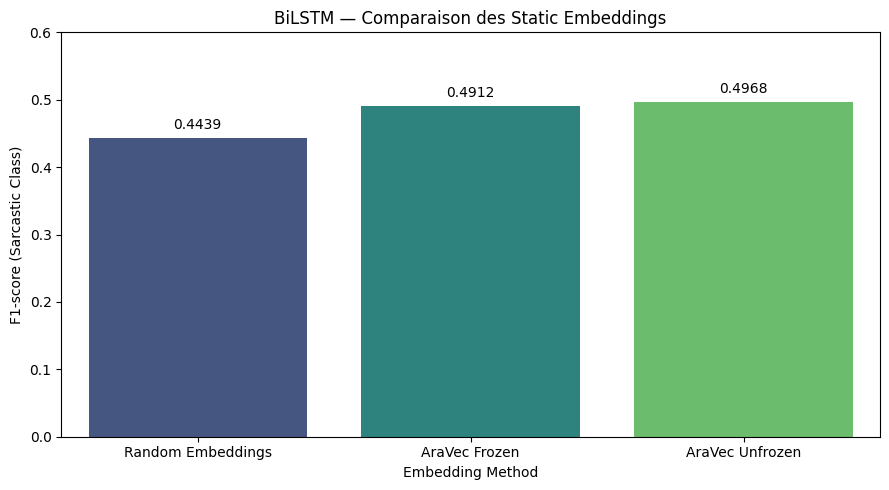

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

results_aravec = pd.DataFrame({
    "Model": [
        "Random Embeddings",
        "AraVec Frozen",
        "AraVec Unfrozen"
    ],
    "F1-score": [0.4439, 0.4912, 0.4968]
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=results_aravec,
    x="Model",
    y="F1-score",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=4)

plt.title("BiLSTM — Comparaison des Static Embeddings")
plt.xlabel("Embedding Method")
plt.ylabel("F1-score (Sarcastic Class)")
plt.ylim(0, 0.6)

plt.tight_layout()
plt.show()

Conclusion : AraVec Unfrozen obtient le meilleur F1-score (0.4968), devant AraVec Frozen (0.4912) et Random Embeddings (0.4439).

BiLSTM + Attention

In [99]:
import torch
import torch.nn as nn
import numpy as np
import copy
from sklearn.metrics import f1_score

# ======================================
# 1. BiLSTM + Attention
# ======================================

class BiLSTMAttention(nn.Module):
    def __init__(self, matrix, hidden_dim=128):
        super().__init__()

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(matrix, dtype=torch.float32),
            freeze=False,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=100,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Additive Attention
        self.attention = nn.Linear(hidden_dim * 2, hidden_dim)
        self.attention_vector = nn.Linear(hidden_dim, 1, bias=False)

        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, x):
        embedded = self.embedding(x)
        output, _ = self.lstm(embedded)

        # Attention scores
        scores = self.attention_vector(
            torch.tanh(self.attention(output))
        ).squeeze(-1)

        # Masquer les PAD
        mask = x != 0
        scores = scores.masked_fill(~mask, -1e9)

        # Attention weights
        alpha = torch.softmax(scores, dim=1)

        # Context vector
        context = torch.sum(output * alpha.unsqueeze(-1), dim=1)

        logits = self.fc(context)

        return logits, alpha


# ======================================
# 2. Initialisation
# ======================================

torch.manual_seed(42)

model_attention = BiLSTMAttention(embedding_matrix).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.Adam(
    model_attention.parameters(),
    lr=0.001
)

# ======================================
# 3. Training + Early Stopping
# ======================================

best_f1_attention = -1
best_state = None
patience = 3
counter = 0

for epoch in range(15):

    model_attention.train()
    total_loss = 0

    for X, y in train_loader:

        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()

        outputs, _ = model_attention(X)

        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Validation
    model_attention.eval()

    predictions = []
    true_labels = []

    with torch.no_grad():
        for X, y in val_loader:

            outputs, _ = model_attention(X.to(device))
            preds = outputs.argmax(dim=1).cpu().numpy()

            predictions.extend(preds)
            true_labels.extend(y.numpy())

    f1 = f1_score(true_labels, predictions, zero_division=0)

    print(
        f"Epoch {epoch+1} | "
        f"Loss: {total_loss / len(train_loader):.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1_attention:
        best_f1_attention = f1
        best_state = copy.deepcopy(model_attention.state_dict())
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early Stopping")
        break

# ======================================
# 4. Restaurer le meilleur modèle
# ======================================

model_attention.load_state_dict(best_state)

print("\nMeilleur F1 BiLSTM + Attention :", round(best_f1_attention, 4))
print("F1 BiLSTM + AraVec Unfrozen :", round(f1_unfrozen, 4))

Epoch 1 | Loss: 0.5416 | F1: 0.4905
Epoch 2 | Loss: 0.4330 | F1: 0.4863
Epoch 3 | Loss: 0.3404 | F1: 0.5031
Epoch 4 | Loss: 0.2352 | F1: 0.4402
Epoch 5 | Loss: 0.2311 | F1: 0.4553
Epoch 6 | Loss: 0.1494 | F1: 0.4553
Early Stopping

Meilleur F1 BiLSTM + Attention : 0.5031
F1 BiLSTM + AraVec Unfrozen : 0.4968


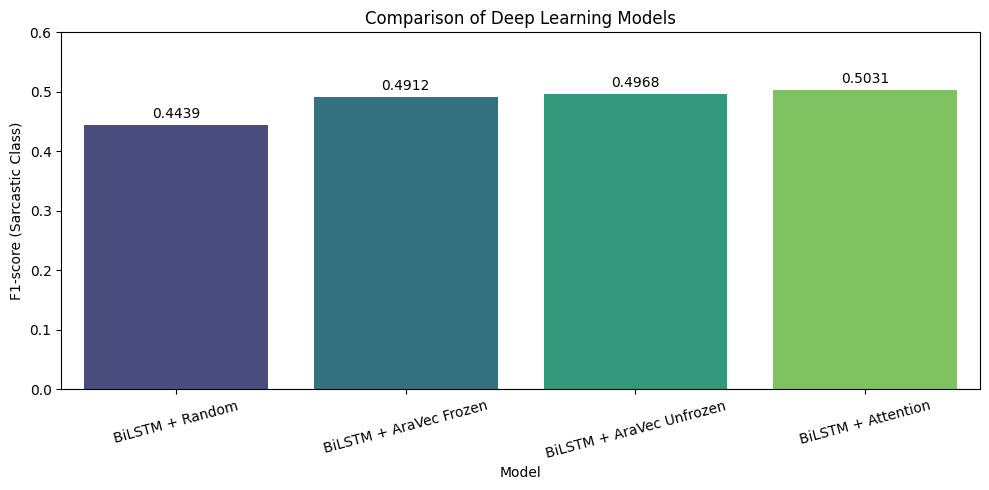

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_dl = pd.DataFrame({
    "Model": [
        "BiLSTM + Random",
        "BiLSTM + AraVec Frozen",
        "BiLSTM + AraVec Unfrozen",
        "BiLSTM + Attention"
    ],
    "F1-score": [0.4439, 0.4912, 0.4968, 0.5031]
})

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=results_dl,
    x="Model",
    y="F1-score",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("Comparison of Deep Learning Models")
plt.xlabel("Model")
plt.ylabel("F1-score (Sarcastic Class)")
plt.ylim(0, 0.6)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

La visualisation montre que BiLSTM + Attention obtient le meilleur résultat parmi les modèles Deep Learning avec un F1-score de 0.5031.
Il dépasse légèrement BiLSTM + AraVec Unfrozen (0.4968), AraVec Frozen (0.4912) et Random Embeddings (0.4439).

# ***Partie C — C3 : Mini-Transformer***

In [102]:
import torch
import torch.nn as nn
import numpy as np
import copy
import math
from sklearn.metrics import f1_score

# ======================================
# 1. Positional Encoding
# ======================================

class PositionalEncoding(nn.Module):
    def __init__(self, d_model=128, max_len=128):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


# ======================================
# 2. Mini-Transformer
# ======================================

class MiniTransformer(nn.Module):
    def __init__(self, vocab_size, use_positional=True):
        super().__init__()

        self.use_positional = use_positional

        self.embedding = nn.Embedding(
            vocab_size, 128, padding_idx=0
        )

        self.positional = PositionalEncoding()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
            enable_nested_tensor=False
        )

        self.fc = nn.Linear(128, 2)

    def forward(self, x):
        mask = (x == 0)

        embedded = self.embedding(x) * math.sqrt(128)

        if self.use_positional:
            embedded = self.positional(embedded)

        output = self.encoder(
            embedded,
            src_key_padding_mask=mask
        )

        # Mean Pooling sans PAD
        valid = (~mask).unsqueeze(-1)
        pooled = (output * valid).sum(dim=1)
        pooled = pooled / valid.sum(dim=1).clamp(min=1)

        return self.fc(pooled)


# ======================================
# 3. Training Function
# ======================================

def train_transformer(use_positional=True):

    torch.manual_seed(42)

    model = MiniTransformer(
        len(vocab),
        use_positional=use_positional
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0001
    )

    best_f1 = -1
    best_state = None
    patience = 3
    counter = 0

    for epoch in range(15):

        model.train()
        total_loss = 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            optimizer.zero_grad()

            outputs = model(X)
            loss = criterion(outputs, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Validation
        model.eval()
        predictions = []
        true_labels = []

        with torch.no_grad():
            for X, y in val_loader:
                outputs = model(X.to(device))
                preds = outputs.argmax(dim=1).cpu().numpy()

                predictions.extend(preds)
                true_labels.extend(y.numpy())

        f1 = f1_score(
            true_labels,
            predictions,
            zero_division=0
        )

        print(
            f"Epoch {epoch+1} | "
            f"Loss: {total_loss/len(train_loader):.4f} | "
            f"F1: {f1:.4f}"
        )

        if f1 > best_f1:
            best_f1 = f1
            best_state = copy.deepcopy(model.state_dict())
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            print("Early Stopping")
            break

    model.load_state_dict(best_state)

    return model, best_f1


# ======================================
# 4. Avec Positional Encoding
# ======================================

print("===== WITH POSITIONAL ENCODING =====")

model_transformer, f1_transformer = train_transformer(
    use_positional=True
)

# ======================================
# 5. Sans Positional Encoding
# ======================================

print("\n===== WITHOUT POSITIONAL ENCODING =====")

model_no_pos, f1_no_pos = train_transformer(
    use_positional=False
)

# ======================================
# 6. Comparaison
# ======================================

import pandas as pd

results_transformer = pd.DataFrame({
    "Model": [
        "BiLSTM + Attention",
        "Mini-Transformer + PE",
        "Mini-Transformer sans PE"
    ],
    "F1-score": [
        0.5031,
        f1_transformer,
        f1_no_pos
    ]
})

display(results_transformer.round(4))

===== WITH POSITIONAL ENCODING =====
Epoch 1 | Loss: 0.6597 | F1: 0.3472
Epoch 2 | Loss: 0.6209 | F1: 0.3519
Epoch 3 | Loss: 0.5896 | F1: 0.3479
Epoch 4 | Loss: 0.5552 | F1: 0.3384
Epoch 5 | Loss: 0.5147 | F1: 0.3569
Epoch 6 | Loss: 0.4644 | F1: 0.3660
Epoch 7 | Loss: 0.4056 | F1: 0.3862
Epoch 8 | Loss: 0.3559 | F1: 0.3843
Epoch 9 | Loss: 0.3058 | F1: 0.3464
Epoch 10 | Loss: 0.2614 | F1: 0.3755
Early Stopping

===== WITHOUT POSITIONAL ENCODING =====
Epoch 1 | Loss: 0.6590 | F1: 0.3357
Epoch 2 | Loss: 0.6216 | F1: 0.3346
Epoch 3 | Loss: 0.5909 | F1: 0.3419
Epoch 4 | Loss: 0.5567 | F1: 0.3784
Epoch 5 | Loss: 0.5145 | F1: 0.3507
Epoch 6 | Loss: 0.4636 | F1: 0.3535
Epoch 7 | Loss: 0.4135 | F1: 0.3852
Epoch 8 | Loss: 0.3594 | F1: 0.3815
Epoch 9 | Loss: 0.3144 | F1: 0.3574
Epoch 10 | Loss: 0.2750 | F1: 0.3499
Early Stopping


,Model,F1-score
0,BiLSTM + Attention,0.5031
1,Mini-Transformer + PE,0.3862
2,Mini-Transformer sans PE,0.3852


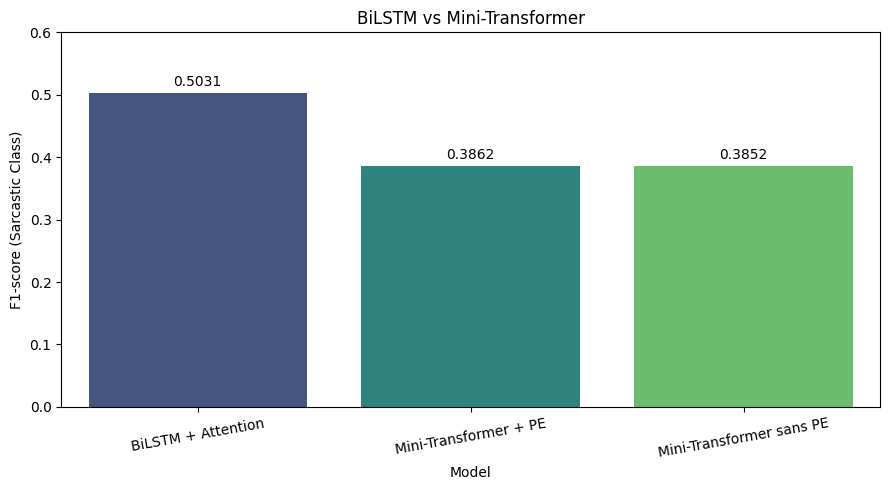

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "BiLSTM + Attention",
        "Mini-Transformer + PE",
        "Mini-Transformer sans PE"
    ],
    "F1-score": [0.5031, 0.3862, 0.3852]
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=results,
    x="Model",
    y="F1-score",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("BiLSTM vs Mini-Transformer")
plt.xlabel("Model")
plt.ylabel("F1-score (Sarcastic Class)")
plt.ylim(0, 0.6)
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

Le BiLSTM + Attention obtient le meilleur F1-score (0.5031), dépassant les deux Mini-Transformers. Le Positional Encoding apporte une amélioration très faible (0.3862 contre 0.3852). Dans cette expérience, le BiLSTM généralise donc mieux sur les données de validation.

# ***Partie C — Étape C4 : Class Imbalance Handling***

In [104]:
from imblearn.over_sampling import RandomOverSampler
from torch.utils.data import TensorDataset, DataLoader

ros = RandomOverSampler(random_state=42)

indices = np.arange(len(y_tr)).reshape(-1, 1)

indices_over, y_over = ros.fit_resample(indices, y_tr)

X_over = X_tr[indices_over.ravel()]

over_loader = DataLoader(
    TensorDataset(
        X_over,
        torch.tensor(y_over, dtype=torch.long)
    ),
    batch_size=32,
    shuffle=True
)

print("Avant :", np.bincount(y_tr))
print("Après :", np.bincount(y_over))

Avant : [9342 1951]
Après : [9342 9342]


Entraînement et optimisation du seuil

In [105]:
from sklearn.metrics import f1_score
import copy

def train_imbalance(method):

    torch.manual_seed(42)
    model = BiLSTMAttention(embedding_matrix).to(device)

    loader = over_loader if method == "Oversampling" else train_loader

    loss_weights = weights if method == "Class Weighting" else None
    criterion = nn.CrossEntropyLoss(weight=loss_weights)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    best_f1 = -1
    best_state = None
    best_threshold = 0.5
    patience = 3
    counter = 0

    for epoch in range(15):
        model.train()
        total_loss = 0

        for X, y in loader:
            X, y = X.to(device), y.to(device)

            optimizer.zero_grad()
            logits, _ = model(X)
            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        probabilities = []

        with torch.no_grad():
            for X, _ in val_loader:
                logits, _ = model(X.to(device))
                probs = torch.softmax(logits, dim=1)[:, 1]
                probabilities.extend(probs.cpu().numpy())

        probabilities = np.array(probabilities)

        if method == "Threshold Tuning":
            thresholds = np.arange(0.05, 0.96, 0.01)
        else:
            thresholds = [0.5]

        scores = [
            f1_score(y_v, probabilities >= t, zero_division=0)
            for t in thresholds
        ]

        index = np.argmax(scores)
        f1 = scores[index]
        threshold = thresholds[index]

        print(f"{method} | Epoch {epoch+1} | F1: {f1:.4f}")

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_state = copy.deepcopy(model.state_dict())
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            print("Early Stopping")
            break

    model.load_state_dict(best_state)
    return model, best_f1, best_threshold


# Oversampling
model_over, f1_over, threshold_over = train_imbalance("Oversampling")

# Threshold Tuning
model_threshold, f1_threshold, threshold_tuned = train_imbalance("Threshold Tuning")

Oversampling | Epoch 1 | F1: 0.4756
Oversampling | Epoch 2 | F1: 0.4143
Oversampling | Epoch 3 | F1: 0.3665
Oversampling | Epoch 4 | F1: 0.4309
Early Stopping
Threshold Tuning | Epoch 1 | F1: 0.5123
Threshold Tuning | Epoch 2 | F1: 0.5092
Threshold Tuning | Epoch 3 | F1: 0.4863
Threshold Tuning | Epoch 4 | F1: 0.4494
Early Stopping


Tableau comparatif

In [106]:
results_imbalance = pd.DataFrame({
    "Method": [
        "Class Weighting",
        "Oversampling",
        "Threshold Tuning"
    ],
    "F1-score": [
        best_f1_attention,
        f1_over,
        f1_threshold
    ]
})

display(results_imbalance.round(4))

,Method,F1-score
0,Class Weighting,0.5031
1,Oversampling,0.4756
2,Threshold Tuning,0.5123


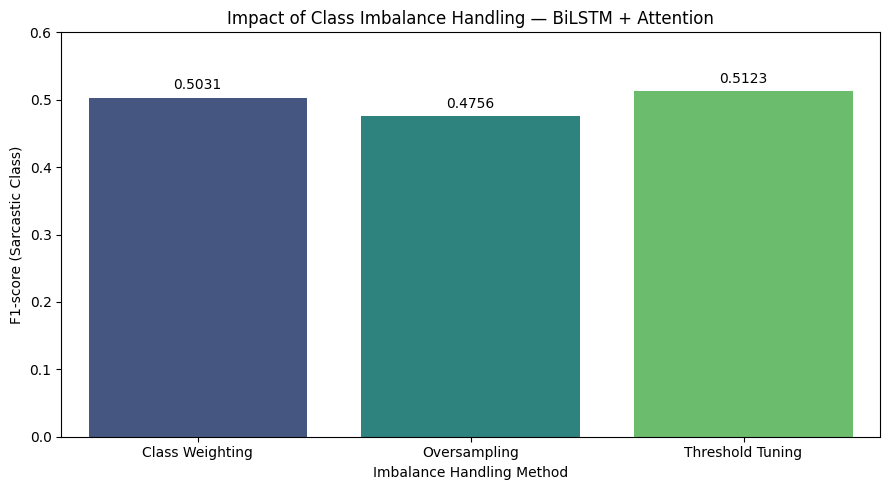

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

results_imbalance = pd.DataFrame({
    "Method": [
        "Class Weighting",
        "Oversampling",
        "Threshold Tuning"
    ],
    "F1-score": [0.5031, 0.4756, 0.5123]
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=results_imbalance,
    x="Method",
    y="F1-score",
    hue="Method",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=4)

plt.title("Impact of Class Imbalance Handling — BiLSTM + Attention")
plt.xlabel("Imbalance Handling Method")
plt.ylabel("F1-score (Sarcastic Class)")
plt.ylim(0, 0.6)

plt.tight_layout()
plt.show()

La méthode Threshold Tuning obtient le meilleur F1-score (0.5123), suivie de Class Weighting (0.5031) et Oversampling (0.4756).
L'optimisation du seuil améliore donc légèrement la détection du sarcasme. Le ré-échantillonnage est moins efficace dans cette expérience.
Meilleur modèle de la Partie C : BiLSTM + AraVec + Attention + Threshold Tuning (F1 = 0.5123).

# ***Étape D.1 — Charger AraBERT Frozen***

In [108]:
import torch
from transformers import AutoTokenizer, AutoModel

model_name = "aubmindlab/bert-base-arabertv02-twitter"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Modèle AraBERT
arabert = AutoModel.from_pretrained(model_name).to(device)

# Geler les paramètres
for param in arabert.parameters():
    param.requires_grad = False

# Mode évaluation
arabert.eval()

print("Device :", device)
print("Hidden size :", arabert.config.hidden_size)

print("Paramètres entraînables :", sum(
    p.numel() for p in arabert.parameters() if p.requires_grad
))

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device : cuda
Hidden size : 768
Paramètres entraînables : 0


# ***Étape D.2 — Extraction des embeddings***

In [109]:
import numpy as np
from tqdm.auto import tqdm

def extract_embeddings(texts, batch_size=16):
    cls_vectors = []
    mean_vectors = []

    for i in tqdm(range(0, len(texts), batch_size)):
        batch = texts[i:i+batch_size]

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = arabert(**inputs)
            hidden = outputs.last_hidden_state

            # CLS
            cls = hidden[:, 0, :]

            # Mean Pooling sans padding
            mask = inputs["attention_mask"].unsqueeze(-1)
            mean = (hidden * mask).sum(dim=1) / mask.sum(dim=1)

        cls_vectors.append(cls.cpu().numpy())
        mean_vectors.append(mean.cpu().numpy())

    return np.vstack(cls_vectors), np.vstack(mean_vectors)


# Extraction Train
X_train_cls, X_train_mean = extract_embeddings(
    train["text_clean"].fillna("").tolist()
)

# Extraction Validation
X_val_cls, X_val_mean = extract_embeddings(
    val["text_clean"].fillna("").tolist()
)

print("CLS Train :", X_train_cls.shape)
print("Mean Train :", X_train_mean.shape)
print("CLS Validation :", X_val_cls.shape)
print("Mean Validation :", X_val_mean.shape)

  0%|          | 0/706 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

CLS Train : (11293, 768)
Mean Train : (11293, 768)
CLS Validation : (1255, 768)
Mean Validation : (1255, 768)


# ***Partie D — Étape D.3 : Logistic Regression (CLS vs Mean Pooling):***

In [110]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

embeddings = {
    "CLS": (X_train_cls, X_val_cls),
    "Mean Pooling": (X_train_mean, X_val_mean)
}

results_d1 = []
models_d1 = {}

thresholds = np.arange(0.05, 0.96, 0.01)

for name, (X_tr, X_v) in embeddings.items():

    # Logistic Regression
    model = LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_tr, y_train)

    # Probabilités sur Validation
    probabilities = model.predict_proba(X_v)[:, 1]

    # Optimisation du seuil
    scores = [
        f1_score(y_val, probabilities >= t)
        for t in thresholds
    ]

    best_idx = np.argmax(scores)
    threshold = thresholds[best_idx]

    predictions = (probabilities >= threshold).astype(int)

    results_d1.append({
        "Embedding": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions)
    })

    models_d1[name] = (model, threshold)

# Tableau comparatif
results_d1_df = pd.DataFrame(results_d1)
display(results_d1_df.round(4))

,Embedding,Threshold,Precision,Recall,F1-score
0,CLS,0.55,0.5224,0.7512,0.6163
1,Mean Pooling,0.72,0.5873,0.6820,0.6311


# ***Partie D — Visualisation CLS vs Mean Pooling***

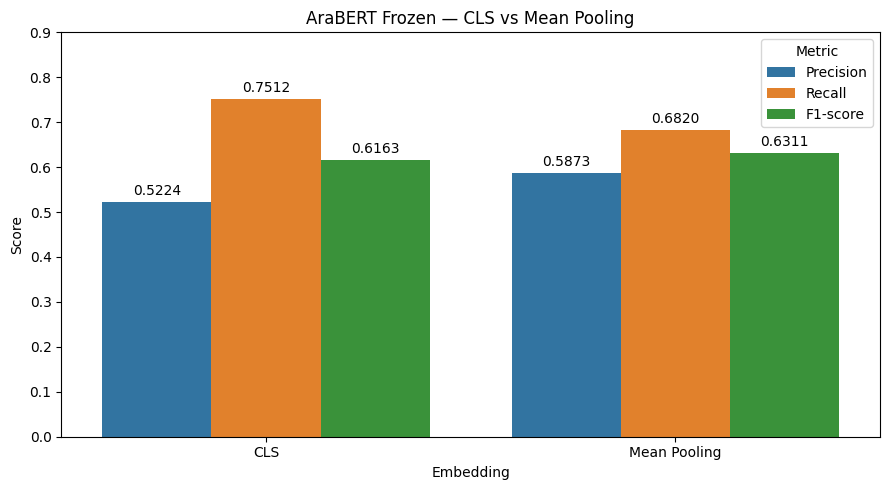

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

data_plot = results_d1_df.melt(
    id_vars="Embedding",
    value_vars=["Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=data_plot,
    x="Embedding",
    y="Score",
    hue="Metric"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("AraBERT Frozen — CLS vs Mean Pooling")
plt.ylabel("Score")
plt.ylim(0, 0.9)
plt.tight_layout()
plt.show()

Mean Pooling obtient le meilleur F1-score (0.6311) contre 0.6163 pour CLS. Il offre une meilleure précision, tandis que CLS possède un meilleur rappel.
Le modèle AraBERT Frozen + Mean Pooling + Logistic Regression dépasse également notre baseline Linear SVM (0.5506).

# ***Partie D — Étape D.2 : AraBERT Frozen + BiLSTM + Attention***

In [112]:
import torch
import torch.nn as nn

class FrozenAraBERTBiLSTM(nn.Module):
    def __init__(self, encoder, hidden_dim=128):
        super().__init__()

        self.encoder = encoder

        for param in self.encoder.parameters():
            param.requires_grad = False

        self.lstm = nn.LSTM(
            input_size=768,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.Linear(hidden_dim * 2, hidden_dim)
        self.attention_vector = nn.Linear(hidden_dim, 1, bias=False)
        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, input_ids, attention_mask):

        self.encoder.eval()

        with torch.no_grad():
            hidden = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            ).last_hidden_state

        output, _ = self.lstm(hidden)

        scores = self.attention_vector(
            torch.tanh(self.attention(output))
        ).squeeze(-1)

        scores = scores.masked_fill(attention_mask == 0, -1e9)

        alpha = torch.softmax(scores, dim=1)

        context = torch.sum(
            output * alpha.unsqueeze(-1),
            dim=1
        )

        logits = self.fc(context)

        return logits, alpha


model_d2 = FrozenAraBERTBiLSTM(arabert).to(device)

print("Modèle créé avec succès !")
print("Paramètres entraînables :", sum(
    p.numel() for p in model_d2.parameters() if p.requires_grad
))

Modèle créé avec succès !
Paramètres entraînables : 953090


Training du modèle

In [113]:
import torch
import numpy as np
import copy
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

# Préparation des labels
y_train_d = train["sarcasm"].astype(int).to_numpy()
y_val_d = val["sarcasm"].astype(int).to_numpy()

# DataLoaders AraBERT
train_loader_d = DataLoader(
    TensorDataset(
        train_enc["input_ids"],
        train_enc["attention_mask"],
        torch.tensor(y_train_d, dtype=torch.long)
    ),
    batch_size=16,
    shuffle=True
)

val_loader_d = DataLoader(
    TensorDataset(
        val_enc["input_ids"],
        val_enc["attention_mask"],
        torch.tensor(y_val_d, dtype=torch.long)
    ),
    batch_size=16
)

# Pondération des classes
class_weights_d = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train_d
)

criterion = torch.nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights_d, dtype=torch.float32).to(device)
)

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_d2.parameters()),
    lr=0.001
)

# Entraînement
best_f1_d2 = -1
best_state = None
patience = 3
counter = 0

for epoch in range(10):

    model_d2.train()
    total_loss = 0

    for input_ids, attention_mask, labels in train_loader_d:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits, _ = model_d2(input_ids, attention_mask)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Validation
    model_d2.eval()
    predictions = []

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader_d:
            logits, _ = model_d2(
                input_ids.to(device),
                attention_mask.to(device)
            )
            predictions.extend(logits.argmax(dim=1).cpu().numpy())

    f1 = f1_score(y_val_d, predictions, zero_division=0)

    print(
        f"Epoch {epoch+1} | "
        f"Loss: {total_loss / len(train_loader_d):.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1_d2:
        best_f1_d2 = f1
        best_state = copy.deepcopy({
            k: v.cpu().clone()
            for k, v in model_d2.state_dict().items()
            if not k.startswith("encoder.")
        })
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early Stopping")
        break

# Restaurer les meilleures couches entraînables
model_d2.load_state_dict(best_state, strict=False)

print("\nMeilleur F1 Validation :", round(best_f1_d2, 4))

Epoch 1 | Loss: 0.4410 | F1: 0.6426
Epoch 2 | Loss: 0.3706 | F1: 0.6536
Epoch 3 | Loss: 0.3074 | F1: 0.6039
Epoch 4 | Loss: 0.2374 | F1: 0.6429
Epoch 5 | Loss: 0.1652 | F1: 0.6203
Early Stopping

Meilleur F1 Validation : 0.6536


Notre score est calculé sur Validation.

# ***Partie E — Fine-Tuning des Transformers***

In [115]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_name = "aubmindlab/bert-base-arabertv02-twitter"

tokenizer_ft = AutoTokenizer.from_pretrained(model_name)

model_ft = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    ignore_mismatched_sizes=True
).to(device)

# Tous les paramètres sont entraînables
for param in model_ft.parameters():
    param.requires_grad = True

print("Device :", device)
print("Paramètres entraînables :", sum(
    p.numel() for p in model_ft.parameters() if p.requires_grad
))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device : cuda
Paramètres entraînables : 135194882


# ***Partie E.1 — Fine-Tuning AraBERT (Mono-Tâche)***

In [117]:
import torch
import numpy as np
import copy
import random
from torch.utils.data import TensorDataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.utils.class_weight import compute_class_weight

# ==========================================
# 1. Configuration
# ==========================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

MODEL_NAME = "aubmindlab/bert-base-arabertv02-twitter"
MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 5
LR = 2e-5

# ==========================================
# 2. Tokenizer et modèle
# ==========================================

tokenizer_ft = AutoTokenizer.from_pretrained(MODEL_NAME)

model_ft = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
).to(device)

# ==========================================
# 3. Préparation Train / Validation
# ==========================================

def encode_data(data):
    return tokenizer_ft(
        data["text_clean"].fillna("").tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

train_encoding = encode_data(train)
val_encoding = encode_data(val)

y_train_ft = train["sarcasm"].astype(int).to_numpy()
y_val_ft = val["sarcasm"].astype(int).to_numpy()

train_loader_ft = DataLoader(
    TensorDataset(
        train_encoding["input_ids"],
        train_encoding["attention_mask"],
        torch.tensor(y_train_ft, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_ft = DataLoader(
    TensorDataset(
        val_encoding["input_ids"],
        val_encoding["attention_mask"],
        torch.tensor(y_val_ft, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE
)

# ==========================================
# 4. Weighted Cross-Entropy
# ==========================================

class_weights_ft = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train_ft
)

weights_ft = torch.tensor(
    class_weights_ft,
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=weights_ft)

# ==========================================
# 5. Optimizer et Scheduler
# ==========================================

optimizer = torch.optim.AdamW(
    model_ft.parameters(),
    lr=LR,
    weight_decay=0.01
)

total_steps = len(train_loader_ft) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

# ==========================================
# 6. Training + Early Stopping
# ==========================================

best_f1_ft = -1
best_state_ft = None
best_epoch = 0
patience = 2
counter = 0

for epoch in range(EPOCHS):

    model_ft.train()
    total_loss = 0

    for input_ids, attention_mask, labels in train_loader_ft:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_ft(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_ft.parameters(), 1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    # ======================================
    # Validation
    # ======================================

    model_ft.eval()
    predictions = []
    true_labels = []

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader_ft:

            outputs = model_ft(
                input_ids=input_ids.to(device),
                attention_mask=attention_mask.to(device)
            )

            preds = outputs.logits.argmax(dim=1).cpu().numpy()

            predictions.extend(preds)
            true_labels.extend(labels.numpy())

    f1 = f1_score(true_labels, predictions, zero_division=0)

    print(
        f"Epoch {epoch+1} | "
        f"Loss: {total_loss / len(train_loader_ft):.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1_ft:
        best_f1_ft = f1
        best_epoch = epoch + 1
        best_state_ft = {
            k: v.detach().cpu().clone()
            for k, v in model_ft.state_dict().items()
        }
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early Stopping")
        break

# ==========================================
# 7. Restaurer le meilleur modèle
# ==========================================

model_ft.load_state_dict(best_state_ft)
model_ft.eval()

print("\nMeilleure époque :", best_epoch)
print("Meilleur F1 Validation :", round(best_f1_ft, 4))

# ==========================================
# 8. Sauvegarde
# ==========================================

model_ft.save_pretrained("arabert_finetuned")
tokenizer_ft.save_pretrained("arabert_finetuned")

print("Modèle sauvegardé avec succès !")

Device : cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 | Loss: 0.4932 | F1: 0.6601
Epoch 2 | Loss: 0.3491 | F1: 0.6589
Epoch 3 | Loss: 0.2198 | F1: 0.6224
Early Stopping

Meilleure époque : 1
Meilleur F1 Validation : 0.6601


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé avec succès !


# ***Partie E1.2 — MARBERTv2 Fine-Tuning (Mono-Tâche)***

In [118]:
import torch
import numpy as np
import random
import copy

from torch.utils.data import TensorDataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

# ==========================================
# 1. Configuration
# ==========================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "UBC-NLP/MARBERTv2"
MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 5
LR = 2e-5

print("Device :", device)

# ==========================================
# 2. Charger MARBERTv2
# ==========================================

tokenizer_marbert = AutoTokenizer.from_pretrained(MODEL_NAME)

model_marbert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
).to(device)

# ==========================================
# 3. Préparer Train / Validation
# ==========================================

def encode_marbert(data):
    return tokenizer_marbert(
        data["text_clean"].fillna("").tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

train_enc_marbert = encode_marbert(train)
val_enc_marbert = encode_marbert(val)

y_train_marbert = train["sarcasm"].astype(int).to_numpy()
y_val_marbert = val["sarcasm"].astype(int).to_numpy()

train_loader_marbert = DataLoader(
    TensorDataset(
        train_enc_marbert["input_ids"],
        train_enc_marbert["attention_mask"],
        torch.tensor(y_train_marbert, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_marbert = DataLoader(
    TensorDataset(
        val_enc_marbert["input_ids"],
        val_enc_marbert["attention_mask"],
        torch.tensor(y_val_marbert, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE
)

# ==========================================
# 4. Weighted Cross-Entropy
# ==========================================

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train_marbert
)

criterion = torch.nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=device
    )
)

# ==========================================
# 5. Optimizer + Scheduler
# ==========================================

optimizer = torch.optim.AdamW(
    model_marbert.parameters(),
    lr=LR,
    weight_decay=0.01
)

total_steps = len(train_loader_marbert) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

# ==========================================
# 6. Training + Early Stopping
# ==========================================

best_f1_marbert = -1
best_state_marbert = None
best_epoch_marbert = 0

patience = 2
counter = 0

for epoch in range(EPOCHS):

    model_marbert.train()
    total_loss = 0

    for input_ids, attention_mask, labels in train_loader_marbert:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_marbert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_marbert.parameters(), 1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    # Validation
    model_marbert.eval()
    predictions = []

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader_marbert:

            outputs = model_marbert(
                input_ids=input_ids.to(device),
                attention_mask=attention_mask.to(device)
            )

            preds = outputs.logits.argmax(dim=1).cpu().numpy()
            predictions.extend(preds)

    f1 = f1_score(y_val_marbert, predictions, zero_division=0)

    print(
        f"Epoch {epoch+1} | "
        f"Loss: {total_loss / len(train_loader_marbert):.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1_marbert:
        best_f1_marbert = f1
        best_epoch_marbert = epoch + 1

        best_state_marbert = {
            k: v.detach().cpu().clone()
            for k, v in model_marbert.state_dict().items()
        }

        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early Stopping")
        break

# ==========================================
# 7. Restaurer + Sauvegarder
# ==========================================

model_marbert.load_state_dict(best_state_marbert)
model_marbert.eval()

print("\nMeilleure époque :", best_epoch_marbert)
print("Meilleur F1 MARBERTv2 :", round(best_f1_marbert, 4))

model_marbert.save_pretrained("marbertv2_finetuned")
tokenizer_marbert.save_pretrained("marbertv2_finetuned")

print("MARBERTv2 sauvegardé !")

Device : cuda


config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/439 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1 | Loss: 0.4957 | F1: 0.6205
Epoch 2 | Loss: 0.3374 | F1: 0.6239
Epoch 3 | Loss: 0.2103 | F1: 0.6200
Epoch 4 | Loss: 0.1154 | F1: 0.6578
Epoch 5 | Loss: 0.0672 | F1: 0.6298

Meilleure époque : 4
Meilleur F1 MARBERTv2 : 0.6578


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

MARBERTv2 sauvegardé !


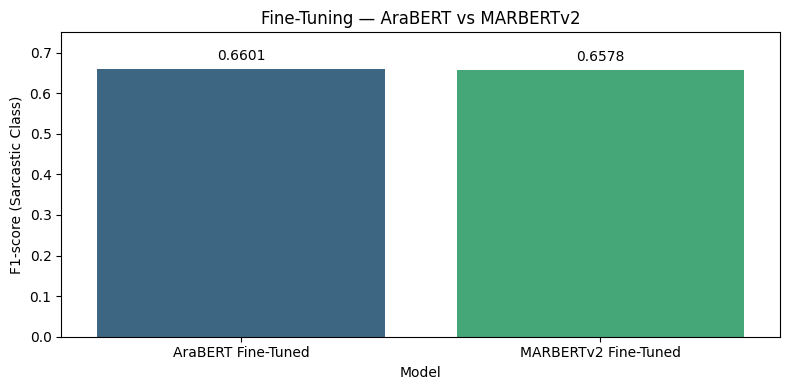

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

results_e1 = pd.DataFrame({
    "Model": ["AraBERT Fine-Tuned", "MARBERTv2 Fine-Tuned"],
    "F1-score": [0.6601, 0.6578]
})

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=results_e1,
    x="Model",
    y="F1-score",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=4)

plt.ylim(0, 0.75)
plt.title("Fine-Tuning — AraBERT vs MARBERTv2")
plt.ylabel("F1-score (Sarcastic Class)")
plt.tight_layout()
plt.show()

Les deux modèles présentent des performances très proches. AraBERT obtient le meilleur F1-score (0.6601), contre 0.6578 pour MARBERTv2, soit un écart de seulement 0.0023. Cette différence ne suffit pas à établir une supériorité générale d'AraBERT.

# ***Partie E2 — Multi-Task Learning : Sarcasme + Sentiment***

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import random
import copy
import gc

from transformers import AutoTokenizer, AutoModel
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

# ================================
# 1. Configuration
# ================================

SEED = 42
MODEL_NAME = "aubmindlab/bert-base-arabertv02-twitter"

MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 5
LR = 2e-5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Device :", device)

# ================================
# 2. Préparation des données
# ================================

tokenizer_mt = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode_data(data):
    return tokenizer_mt(
        data["text_clean"].fillna("").tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

train_enc_mt = encode_data(train)
val_enc_mt = encode_data(val)

sentiment_map = {
    "NEG": 0,
    "NEU": 1,
    "POS": 2
}

y_train_sarc = train["sarcasm"].astype(int).to_numpy()
y_val_sarc = val["sarcasm"].astype(int).to_numpy()

y_train_sent = train["sentiment"].str.upper().map(sentiment_map)
y_val_sent = val["sentiment"].str.upper().map(sentiment_map)

assert y_train_sent.notna().all()
assert y_val_sent.notna().all()

# ================================
# 3. DataLoaders
# ================================

train_dataset = TensorDataset(
    train_enc_mt["input_ids"],
    train_enc_mt["attention_mask"],
    torch.tensor(y_train_sarc, dtype=torch.long),
    torch.tensor(y_train_sent.to_numpy(), dtype=torch.long)
)

val_dataset = TensorDataset(
    val_enc_mt["input_ids"],
    val_enc_mt["attention_mask"],
    torch.tensor(y_val_sarc, dtype=torch.long),
    torch.tensor(y_val_sent.to_numpy(), dtype=torch.long)
)

train_loader_mt = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_mt = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE
)

# ================================
# 4. Architecture Multi-Task
# ================================

class MultiTaskModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(MODEL_NAME)

        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(0.1)

        self.sarc_head = nn.Linear(hidden_size, 2)
        self.sent_head = nn.Linear(hidden_size, 3)

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        cls = outputs.last_hidden_state[:, 0, :]
        cls = self.dropout(cls)

        sarc_logits = self.sarc_head(cls)
        sent_logits = self.sent_head(cls)

        return sarc_logits, sent_logits

# ================================
# 5. Class Weighting
# ================================

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train_sarc
)

weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

# ================================
# 6. Training Function
# ================================

def train_multitask(lam):

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = MultiTaskModel().to(device)

    loss_sarc = nn.CrossEntropyLoss(weight=weights)
    loss_sent = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=0.01
    )

    best_f1 = -1
    best_state = None
    best_epoch = 0
    counter = 0
    patience = 2

    for epoch in range(EPOCHS):

        model.train()
        total_loss = 0

        for ids, mask, y_sarc, y_sent in train_loader_mt:

            ids = ids.to(device)
            mask = mask.to(device)
            y_sarc = y_sarc.to(device)
            y_sent = y_sent.to(device)

            optimizer.zero_grad()

            logits_sarc, logits_sent = model(ids, mask)

            loss = (
                loss_sarc(logits_sarc, y_sarc)
                + lam * loss_sent(logits_sent, y_sent)
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()
            total_loss += loss.item()

        # Validation
        model.eval()
        predictions = []

        with torch.no_grad():

            for ids, mask, _, _ in val_loader_mt:

                ids = ids.to(device)
                mask = mask.to(device)

                logits_sarc, _ = model(ids, mask)

                preds = logits_sarc.argmax(dim=1)
                predictions.extend(preds.cpu().numpy())

        f1 = f1_score(
            y_val_sarc,
            predictions,
            zero_division=0
        )

        print(
            f"Lambda {lam} | Epoch {epoch+1} | "
            f"Loss: {total_loss/len(train_loader_mt):.4f} | "
            f"F1: {f1:.4f}"
        )

        if f1 > best_f1:
            best_f1 = f1
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            counter = 0
        else:
            counter += 1

        if counter >= patience:
            print("Early Stopping")
            break

    model.load_state_dict(best_state)

    # Sauvegarder chaque modèle
    torch.save(
        best_state,
        f"multitask_lambda_{lam}.pt"
    )

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_f1, best_epoch

# ================================
# 7. Comparaison des lambdas
# ================================

results_mt = []

for lam in [0.3, 0.5, 1.0]:

    print(f"\n===== MULTI-TASK λ = {lam} =====")

    f1, epoch = train_multitask(lam)

    results_mt.append({
        "Lambda": lam,
        "Best Epoch": epoch,
        "F1-score": f1
    })

results_mt_df = pd.DataFrame(results_mt)

display(results_mt_df.round(4))

# ================================
# 8. Comparaison avec Mono-Task
# ================================

best_multi = results_mt_df["F1-score"].max()

print("AraBERT Mono-Task :", 0.6601)
print("Best Multi-Task :", round(best_multi, 4))

Device : cuda

===== MULTI-TASK λ = 0.3 =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Lambda 0.3 | Epoch 1 | Loss: 0.6680 | F1: 0.6290
Lambda 0.3 | Epoch 2 | Loss: 0.4697 | F1: 0.6517
Lambda 0.3 | Epoch 3 | Loss: 0.3282 | F1: 0.6497
Lambda 0.3 | Epoch 4 | Loss: 0.2113 | F1: 0.6379
Early Stopping

===== MULTI-TASK λ = 0.5 =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Lambda 0.5 | Epoch 1 | Loss: 0.7921 | F1: 0.6311
Lambda 0.5 | Epoch 2 | Loss: 0.5588 | F1: 0.6569
Lambda 0.5 | Epoch 3 | Loss: 0.3950 | F1: 0.6540
Lambda 0.5 | Epoch 4 | Loss: 0.2570 | F1: 0.6788
Lambda 0.5 | Epoch 5 | Loss: 0.1716 | F1: 0.6344

===== MULTI-TASK λ = 1.0 =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Lambda 1.0 | Epoch 1 | Loss: 1.1076 | F1: 0.6298
Lambda 1.0 | Epoch 2 | Loss: 0.7827 | F1: 0.6571


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Récupérer les résultats Multi-Task
comparison = pd.concat([
    pd.DataFrame({
        "Model": ["AraBERT Mono-Task"],
        "F1-score": [0.6601]
    }),
    pd.DataFrame({
        "Model": [
            f"Multi-Task λ={lam}"
            for lam in results_mt_df["Lambda"]
        ],
        "F1-score": results_mt_df["F1-score"].values
    })
], ignore_index=True)

display(comparison.round(4))

# Visualisation
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=comparison,
    x="Model",
    y="F1-score",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("AraBERT — Mono-Task vs Multi-Task")
plt.ylabel("F1-score (Sarcastic Class)")
plt.ylim(0, 0.8)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

NameError: name 'results_mt_df' is not defined

Partie F.1 — Comparaison des distributions Train / Validation / Test

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Charger les données officielles
BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"

df = pd.read_csv(BASE + "training_data.csv")
test = pd.read_csv(BASE + "testing_data.csv")

# Séparation Train / Validation
train, val = train_test_split(
    df,
    test_size=0.10,
    random_state=42,
    stratify=df["sarcasm"]
)

print("Train :", train.shape)
print("Validation :", val.shape)
print("Test :", test.shape)

Train : (11293, 4)
Validation : (1255, 4)
Test : (3000, 4)


,Dataset,Tweets,Sarcastic (%),Non-Sarcastic (%)
0,Train,11293,17.28,82.72
1,Validation,1255,17.29,82.71
2,Test,3000,27.37,72.63


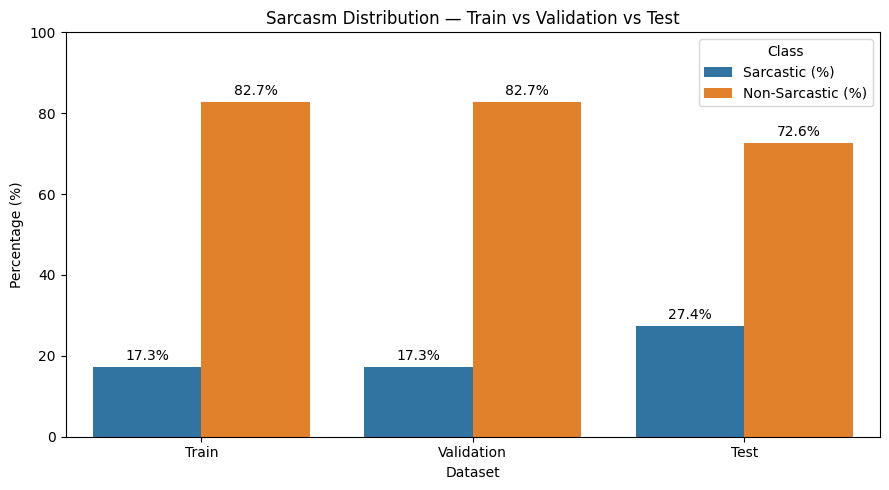

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculer les distributions
datasets = {
    "Train": train,
    "Validation": val,
    "Test": test
}

results_f1 = []

for name, data in datasets.items():
    results_f1.append({
        "Dataset": name,
        "Tweets": len(data),
        "Sarcastic (%)": data["sarcasm"].astype(int).mean() * 100,
        "Non-Sarcastic (%)": (1 - data["sarcasm"].astype(int).mean()) * 100
    })

results_f1 = pd.DataFrame(results_f1)

display(results_f1.round(2))

# 2. Visualisation
data_plot = results_f1.melt(
    id_vars="Dataset",
    value_vars=["Sarcastic (%)", "Non-Sarcastic (%)"],
    var_name="Class",
    value_name="Percentage"
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=data_plot,
    x="Dataset",
    y="Percentage",
    hue="Class"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Sarcasm Distribution — Train vs Validation vs Test")
plt.xlabel("Dataset")
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [7]:
import os

model_path = "multitask_lambda_0.5.pt"

if os.path.exists(model_path):
    print("Modèle disponible !")
else:
    print("Modèle introuvable : il faut restaurer le checkpoint.")

Modèle introuvable : il faut restaurer le checkpoint.


In [8]:
from google.colab import drive
import os

drive.mount('/content/drive')

# Chercher les modèles sauvegardés
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.pt', '.pth', '.safetensors')):
            print(os.path.join(root, file))

Mounted at /content/drive


In [9]:
import os

for root, dirs, files in os.walk("/content"):
    if root.startswith("/content/drive"):
        continue

    for file in files:
        if file.endswith((".pt", ".pth", ".safetensors")):
            print(os.path.join(root, file))

In [11]:
import torch

print("GPU disponible :", torch.cuda.is_available())

GPU disponible : False



# ***Partie F — F2 : Analyse des dialectes arabes***





Dialectes — Train
dialect
msa       7695
egypt     2415
gulf       576
levant     569
magreb      38
Name: count, dtype: int64

Dialectes — Test
dialect
msa       2323
gulf       322
egypt      306
levant      47
magreb       2
Name: count, dtype: int64


,Train,Test
dialect,,
egypt,34.62,50.65
gulf,24.83,17.70
levant,21.44,29.79
magreb,39.47,0.00
msa,10.85,25.61


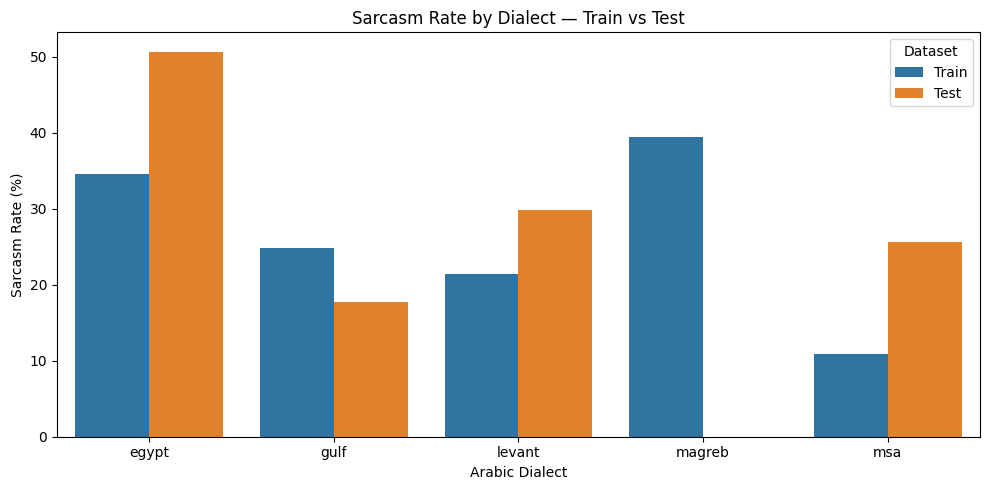

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nombre de tweets par dialecte
dialect_train = train["dialect"].value_counts()
dialect_test = test["dialect"].value_counts()

print("Dialectes — Train")
print(dialect_train)

print("\nDialectes — Test")
print(dialect_test)

# Taux de sarcasme par dialecte
results_dialect = pd.concat([
    train.groupby("dialect")["sarcasm"].mean().mul(100).rename("Train"),
    test.groupby("dialect")["sarcasm"].mean().mul(100).rename("Test")
], axis=1)

display(results_dialect.round(2))

# Visualisation
results_plot = results_dialect.reset_index().melt(
    id_vars="dialect",
    var_name="Dataset",
    value_name="Sarcasm Rate (%)"
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=results_plot,
    x="dialect",
    y="Sarcasm Rate (%)",
    hue="Dataset"
)

plt.title("Sarcasm Rate by Dialect — Train vs Test")
plt.xlabel("Arabic Dialect")
plt.ylabel("Sarcasm Rate (%)")
plt.tight_layout()
plt.show()

# ***Partie F — F3 : Shortcut Analysis (URL et Mentions)***

,Dataset,Feature,Presence,Tweets,Sarcasm Rate (%)
0,Train,has_url,Avec,4302,6.58
1,Train,has_url,Sans,6991,23.86
2,Train,has_mention,Avec,2638,16.64
3,Train,has_mention,Sans,8655,17.47
4,Test,has_url,Avec,440,3.64
5,Test,has_url,Sans,2560,31.45
6,Test,has_mention,Avec,23,0.00
7,Test,has_mention,Sans,2977,27.58


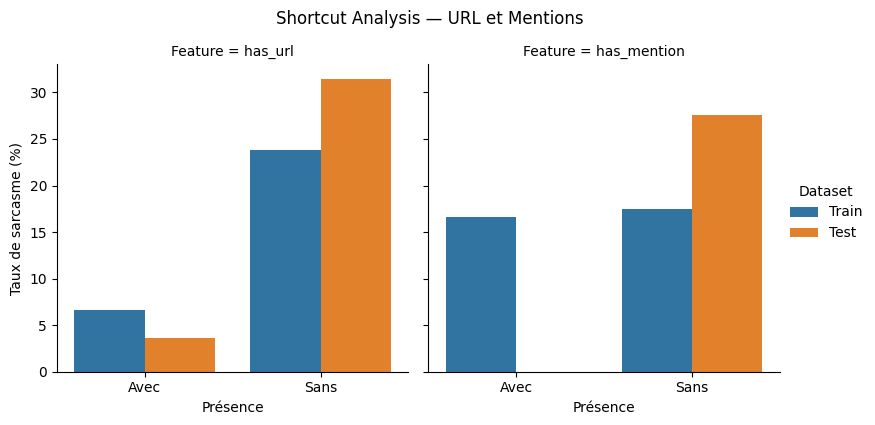

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Détecter URL et mentions
for data in [train, test]:
    data["has_url"] = data["tweet"].str.contains(
        r"https?://\S+|www\.\S+", na=False
    )
    data["has_mention"] = data["tweet"].str.contains(
        r"@\w+", na=False
    )

# 2. Calculer le taux de sarcasme
results = []

for name, data in [("Train", train), ("Test", test)]:
    for feature in ["has_url", "has_mention"]:
        for presence in [True, False]:
            subset = data[data[feature] == presence]

            results.append({
                "Dataset": name,
                "Feature": feature,
                "Presence": "Avec" if presence else "Sans",
                "Tweets": len(subset),
                "Sarcasm Rate (%)": (
                    subset["sarcasm"].astype(int).mean() * 100
                )
            })

results_shortcuts = pd.DataFrame(results)
display(results_shortcuts.round(2))

# 3. Visualisation
g = sns.catplot(
    data=results_shortcuts,
    x="Presence",
    y="Sarcasm Rate (%)",
    hue="Dataset",
    col="Feature",
    kind="bar",
    height=4,
    aspect=1
)

g.set_axis_labels("Présence", "Taux de sarcasme (%)")
g.fig.suptitle("Shortcut Analysis — URL et Mentions", y=1.05)

plt.show()

La présence d'une URL est fortement associée à un taux de sarcasme plus faible, aussi bien dans Train (6,58 % contre 23,86 %) que dans Test (3,64 % contre 31,45 %).
En revanche, les mentions présentent une faible différence dans Train, mais une différence importante dans Test, où seulement 23 tweets contiennent une mention.
Ces résultats suggèrent l'existence de shortcuts, notamment pour les URL, et montrent un changement de distribution entre Train et Test.

# ***Partie F4 — Sarcasm Cues Ablation***

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 5.4 MB/s eta 0:00:00


,Indice,Présence,Tweets,Sarcasm Rate (%)
0,Emoji,Avec,488,6.15
1,Emoji,Sans,2512,31.49
2,Rires,Avec,96,56.25
3,Rires,Sans,2904,26.41
4,Ponctuation répétée,Avec,270,49.63
5,Ponctuation répétée,Sans,2730,25.16


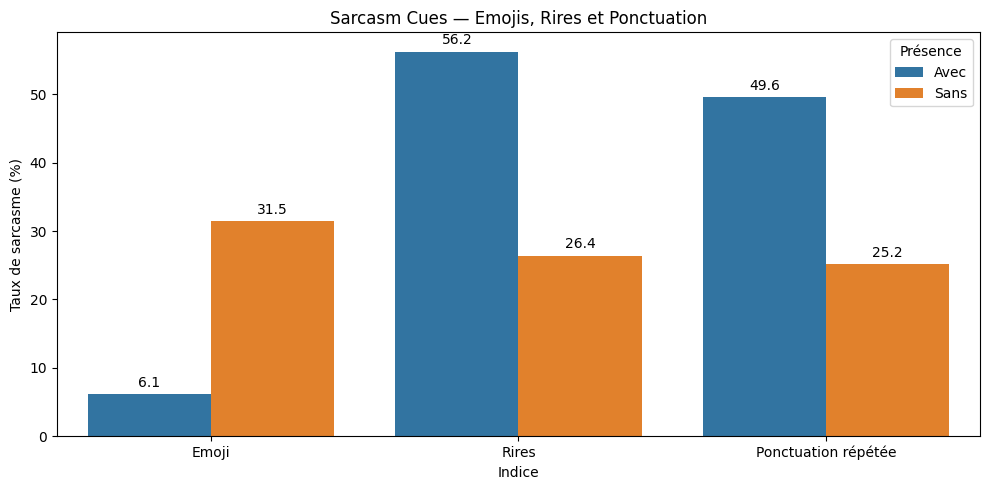

In [14]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

!pip -q install emoji
import emoji

# Détection des indices
def detect_cues(text):
    text = str(text)

    return pd.Series({
        "Emoji": bool(emoji.emoji_list(text)),
        "Rires": bool(re.search(r"ه{3,}", text)),
        "Ponctuation répétée": bool(re.search(r"[!?؟]{2,}", text))
    })

# Analyse sur Test officiel
cues = test["tweet"].fillna("").apply(detect_cues)

results_cues = []

for feature in cues.columns:
    for presence in [True, False]:
        subset = test[cues[feature] == presence]

        results_cues.append({
            "Indice": feature,
            "Présence": "Avec" if presence else "Sans",
            "Tweets": len(subset),
            "Sarcasm Rate (%)": subset["sarcasm"].astype(int).mean() * 100
        })

results_cues = pd.DataFrame(results_cues)

display(results_cues.round(2))

# Visualisation
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=results_cues,
    x="Indice",
    y="Sarcasm Rate (%)",
    hue="Présence"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.title("Sarcasm Cues — Emojis, Rires et Ponctuation")
plt.ylabel("Taux de sarcasme (%)")
plt.tight_layout()
plt.show()

Étape F5 — Bootstrap sur la distribution du sarcasme

In [15]:
import numpy as np

y_test = test["sarcasm"].astype(int).to_numpy()

rng = np.random.default_rng(42)

bootstrap_rates = []

for i in range(1000):
    sample = rng.choice(y_test, size=len(y_test), replace=True)
    bootstrap_rates.append(sample.mean())

ci_low, ci_high = np.percentile(bootstrap_rates, [2.5, 97.5])

print("Taux de sarcasme :", round(y_test.mean() * 100, 2), "%")
print("IC 95 % :", round(ci_low * 100, 2),
      "% -", round(ci_high * 100, 2), "%")

Taux de sarcasme : 27.37 %
IC 95 % : 25.63 % - 29.0 %
